# Modularity on the Karate Club Graph
## Recursive spectral community detection and node-metric evolution

**Course:** DSC212 — Graph Theory Module (Research Assignment)

**Student:** Samarth Kadabagavi · **Institution:** IISER,TVM

**Date:** November 2026 · **Tools:** Python, NumPy, NetworkX and Matplotlib only (plus the Python standard library)

> **How to run.** Choose *Kernel → Restart & Run All*. The notebook needs no input, no external file and no internet connection. It is deterministic (fixed layout seed, no random numbers) and runs in well under a minute. Copies of all figures are also written to a `figures/` folder next to the notebook.

## 1. Introduction and problem statement

In the early 1970s Wayne Zachary observed the 34 members of a university karate club and recorded who interacted with whom outside class (Zachary, 1977). The result is a graph with $n=34$ vertices and $m=78$ edges. During the study a dispute between the instructor ("Mr. Hi") and the club's administrator (the "Officer") split the club into two factions. Because the network was recorded *before* the split, it poses a clean question: **can a method that sees only the graph recover the fault line that later divided the club?**

The handout answers with *modularity*, a quality function that rewards a division of the network into communities when it contains more edges inside the groups than a degree-preserving random graph would. Maximizing modularity exactly is hard, so Newman (2006) relaxes it to an eigenvalue problem: the **leading eigenvector of the modularity matrix** proposes a two-way split, and **recursive bisection** turns this into a method that finds many communities.

**Tasks (from the handout by Prof)**
1. Implement recursive spectral modularity partitioning from scratch (NumPy and NetworkX).
2. Visualize the graph after every split with the communities in different colours (fixed spring layout, nodes labelled by ID).
3. After every split compute degree centrality, betweenness centrality, closeness centrality and the clustering coefficient with NetworkX.
4. Plot the evolution of each metric across iterations for every node.
5. Discuss which nodes stay central across splits and how community structure influences the metrics.

**Conventions used throughout**
- Nodes keep their NetworkX IDs $0,\dots,33$. Zachary's paper numbers the members $1,\dots,34$, so *paper number = ID + 1*. Node 0 is Mr. Hi and node 33 is the Officer.
- **Iteration $t$** is the number of accepted splits so far. $t=0$ is the original graph and the $t$-th accepted split leaves $t+1$ communities. All tables, figures and dictionaries use this numbering.

| # | **[Addition]** | Why it is there |
|---|---|---|
| A1 | Exact modularity gain $\Delta Q$ next to the handout's expression; a split is accepted only if the exact gain is positive (safeguard S2) | The handout's expression is exact only for the first split (Section 2.6), and rounding $\mathbf u_1$ to $\pm1$ can lose the gain promised by $\lambda_1>0$ |
| A2 | Guard against a one-sided sign pattern of $\mathbf u_1$ (safeguard S1) | $\lambda_1>0$ does not guarantee that both groups are non-empty |
| A3 | Independent modularity calculations and validation checks at every step | A notebook that runs is not necessarily a notebook that is correct |
| A4 | Node metrics at iteration 0 (the unsplit graph) | Gives a baseline against which the changes can be measured |
| A5 | One colour *and* one marker shape per community; heatmaps next to the line plots | Readability, also for colour-blind readers and in grey-scale print |

## 2. Background and mathematical formulation

### 2.1 Why modularity?
Cutting as few edges as possible is a poor criterion: isolating one low-degree vertex always gives a tiny cut but is not a community. Modularity asks instead whether a division is *surprising compared with chance*. The chance baseline is the **configuration model**: keep every vertex's degree $k_i$ but pair the $2m$ edge "stubs" at random. A stub of $i$ meets a stub of $j$ with probability about $k_j/2m$, so the expected number of edges between $i$ and $j$ is $k_ik_j/2m$.

### 2.2 The modularity matrix
Let $A\in\{0,1\}^{n\times n}$ be the adjacency matrix and $\mathbf k$ the degree vector ($k_i=\sum_jA_{ij}$, $\sum_ik_i=2m$). The modularity matrix is

$$B=A-\frac{\mathbf k\mathbf k^{\top}}{2m},\qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.$$

$B_{ij}>0$ means that $i$ and $j$ are connected more than chance predicts. Three facts from the handout are used and verified numerically in Section 4:
- **Proposition 1 and Theorem 1.** $B$ is real symmetric, so its eigenvalues are real and it has an orthonormal eigenbasis. This is why a *symmetric* eigensolver (`numpy.linalg.eigh`) is the right tool.
- **Proposition 2.** $B\mathbf 1=\mathbf 0$: every row of $B$ sums to zero, so $0$ is always an eigenvalue of $B$.
- **Corollary 1.** Putting everybody in one community gives $Q=\frac1{4m}\mathbf 1^\top B\mathbf 1=0$.

### 2.3 Modularity of a bipartition —
Encode a division into two groups by $s_i=+1$ (group 1) or $s_i=-1$ (group 2). The number $\tfrac12(1+s_is_j)$ is $1$ if $i$ and $j$ share a group and $0$ otherwise, hence

$$Q=\frac1{2m}\sum_{i,j}B_{ij}\,\frac{1+s_is_j}{2}=\frac1{4m}\Big(\mathbf 1^\top B\mathbf 1+\mathbf s^\top B\mathbf s\Big)=\frac1{4m}\,\mathbf s^\top B\mathbf s ,$$

where the last step uses $\mathbf 1^\top B\mathbf 1=0$ (Proposition 2). This is equation (1) of the handout.

### 2.4 Spectral relaxation and sign rounding —
Maximizing $\mathbf s^\top B\mathbf s$ over $\mathbf s\in\{-1,+1\}^n$ would need $2^n$ evaluations. Relax to real vectors with $\|\mathbf s\|_2=1$. By the **Rayleigh–Ritz theorem**

$$\max_{\|\mathbf s\|_2=1}\mathbf s^\top B\mathbf s=\lambda_1 ,$$

attained at the leading eigenvector $\mathbf u_1$. Entries of $\mathbf u_1$ say how strongly a node is pulled to either side, and we round back to a hard partition with

$$s_i=\begin{cases}+1,&(\mathbf u_1)_i>0,\\-1,&\text{otherwise.}\end{cases}$$

An eigenvector is only defined up to sign: $\mathbf u_1$ and $-\mathbf u_1$ give the same partition with the two groups swapped. To make the names $C^+/C^-$ reproducible we flip $\mathbf u_1$, if necessary, so that its first non-negligible component (the one of the lowest node ID) is positive. This only names the groups; it never changes the partition.

### 2.5 Recursive bisection —
For a community $C\subseteq V$ the **restricted modularity matrix** is the block of the *global* $B$ indexed by $C$:

$$B^{(C)}_{ij}=A_{ij}-\frac{k_ik_j}{2m},\qquad i,j\in C ,$$

where $m$ and $k_i$ always refer to the *original* graph. (Section 4 of the handout speaks of "the modularity matrix for the induced subgraph". In line with Section 3.3 and Theorem 3 we read this as the block of the global $B$. Recomputing $B$ from the subgraph's own degrees and edge count would give a different matrix, to which the gain formulas below do not apply.)

The recursion is:
1. Start with $C=V$.
2. Compute the leading eigenpair $(\lambda_1^{(C)},\mathbf u_1^{(C)})$ of $B^{(C)}$.
3. If $\lambda_1^{(C)}\le0$ stop: $C$ is regarded as indivisible (Theorem 3).
4. Otherwise split $C$ into $C^+$ and $C^-$ by the signs of $\mathbf u_1^{(C)}$ and recurse on both parts.

### 2.6 [Addition] The exact gain of splitting a sub-community
Splitting $C$ into $C^+$ and $C^-$ changes the modularity by

$$\Delta Q=-\frac1m\sum_{i\in C^+,\;j\in C^-}B_{ij}=\frac1{4m}\Big(\mathbf s^\top B^{(C)}\mathbf s-\mathbf 1^\top B^{(C)}\mathbf 1\Big).\qquad(\star)$$

*Derivation.* $Q=\frac1{2m}\sum_{c}\mathbf 1_c^\top B\mathbf 1_c$ over the communities $c$. Writing $\mathbf 1_C=\mathbf 1_{C^+}+\mathbf 1_{C^-}$ and expanding, only the cross term survives: $\Delta Q=-\frac1m\mathbf 1_{C^+}^\top B\mathbf 1_{C^-}$. Finally $\mathbf s^\top B^{(C)}\mathbf s-\mathbf 1^\top B^{(C)}\mathbf 1=-4\,\mathbf 1_{C^+}^\top B\mathbf 1_{C^-}$.

Theorem 3 of the handout states $\Delta Q=\frac1{4m}\mathbf s^\top B^{(C)}\mathbf s$, which leaves out the term $\mathbf 1^\top B^{(C)}\mathbf 1$. The two agree whenever $\mathbf 1^\top B^{(C)}\mathbf 1=0$, which is the case for $C=V$ (Proposition 2), so **the first split is exact**. For a proper sub-community $C\subsetneq V$ one has $\mathbf 1^\top B^{(C)}\mathbf 1=2m\,Q_C$, where $Q_C=\frac{L_C}{m}-\big(\frac{K_C}{2m}\big)^2$ is the contribution of $C$ to the modularity ($L_C$ edges inside $C$, $K_C$ total degree of $C$). For a genuine community $Q_C>0$, so the handout's expression **overstates the gain by $Q_C/2$**. We call it the *nominal gain* $\Delta Q_{\rm nom}$ and always report the exact gain $(\star)$ next to it. (Because $\mathbf s^\top\operatorname{diag}(\mathbf d)\,\mathbf s=\sum_id_i$ for $s_i=\pm1$, the exact gain is the quadratic form of Newman's (2006) generalized matrix $B^{(C)}-\operatorname{diag}(B^{(C)}\mathbf 1)$.)

This matters for two reasons.
1. $\lambda_1^{(C)}>0$ only says that the *relaxed* problem has a positive optimum. By Rayleigh–Ritz, $\mathbf s^\top B^{(C)}\mathbf s\le\lambda_1^{(C)}|C|$ is merely an upper bound that a $\pm1$ vector need not reach.
2. For $C\ne V$ we have $B^{(C)}\mathbf 1\ne\mathbf 0$, so $\mathbf u_1^{(C)}$ may well have a single sign, and rounding then produces no bipartition at all.

We therefore add two transparent safeguards **on top of** the handout's rules. They can only veto a split, never create one:
- **S1 (two-sided sign pattern).** If all entries of $\mathbf u_1$ have the same sign, $C$ is left unsplit.
- **S2 (positive exact gain).** A split is accepted only if its exact gain $(\star)$ is strictly positive.

Every accepted split therefore satisfies the handout's criterion *and* really increases $Q$.

*Remark.* Because of the missing term, the handout's inference "$\lambda_1^{(C)}\le0\Rightarrow\Delta Q\le0$" is rigorous for the nominal gain but not for the exact gain of a proper sub-community. Example: two non-adjacent vertices $a,b$ in a community give $B^{(\{a,b\})}=-\mathbf v\mathbf v^\top/2m$ with $\mathbf v=(k_a,k_b)^\top$, so $\lambda_1=0$, yet separating them has the positive exact gain $k_ak_b/2m^2$. We keep the handout's stopping rule as specified and return to this in the discussion.

### 2.7 Node metrics —
After every accepted split the edges *between* the two new communities are removed from a working graph $G_t$, so $G_t$ keeps only the edges inside communities. Four metrics are then recomputed on $G_t$ with NetworkX:

| Metric | Formula (handout) | NetworkX call | Meaning |
|---|---|---|---|
| Degree centrality | $C_D(i)=\dfrac{k_i}{n-1}$ | `degree_centrality` | share of all other nodes that $i$ touches directly (a hub) |
| Betweenness centrality | $C_B(i)=\sum_{s\ne i\ne t}\dfrac{\sigma_{st}(i)}{\sigma_{st}}$ | `betweenness_centrality` | how often $i$ lies on shortest paths (a bridge or broker) |
| Closeness centrality | $C_C(i)=\dfrac{n-1}{\sum_{j\ne i}d(i,j)}$ | `closeness_centrality` | how quickly $i$ reaches the others (a spreader) |
| Clustering coefficient | $C(i)=\dfrac{2T(i)}{k_i(k_i-1)}$ | `clustering` | share of $i$'s neighbour pairs that are linked (embedded in a tight group) |

**How the metrics are expected to relate to community structure** (to be checked against the numbers in Section 10). *Hubs* (degree) tend to be the centres of their communities. *Brokers* (betweenness) tend to sit on the boundaries between communities, because shortest paths from one community to another have to pass through them. Closeness is high for nodes that reach many others in few steps; once the graph is cut it is limited by the size of the community in which a node ends up. The clustering coefficient is high inside dense groups and low for nodes whose neighbours are spread over several communities.

Removing edges makes $G_t$ **disconnected**, which affects how the conventions of NetworkX must be read:
- *Betweenness.* NetworkX uses Brandes's (2001) algorithm. Its default (`normalized=True`) divides the sum over unordered node pairs by $(n-1)(n-2)/2$, so values lie in $[0,1]$.
- *Closeness.* The handout's formula needs finite distances to all $n-1$ other nodes. NetworkX's default (`wf_improved=True`, Wasserman and Faust, 1994) uses only the $r$ nodes that can be reached and scales by the reached fraction, $C_C(i)=\frac{r}{n-1}\cdot\frac{r}{\sum_{j\text{ reachable}}d(i,j)}$; an isolated node gets $0$. For a connected graph this equals the handout's formula. Section 8 verifies both statements independently.
- *Other metrics.* Degree centrality always divides by $n-1=33$ and betweenness is normalized over all $n=34$ nodes, even after the graph has fallen apart. The clustering coefficient is $0$ when $k_i<2$.

## 3. Libraries and dataset initialization — **[Handout]**

We use NumPy (Harris et al., 2020) for the linear algebra, NetworkX (Hagberg et al., 2008) for the graph and the four metrics, and Matplotlib (Hunter, 2007) for the figures. The helper `check()` below is used for all validation checks in this notebook: it records and prints a check and stops the notebook with an error if the check fails, so a successful run of the whole notebook means that every check passed.

In [ ]:
import os
import textwrap
from collections import deque

import numpy as np
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from networkx.algorithms.community import modularity as nx_modularity  # used only to cross-check our own Q

print(f"NumPy {np.__version__} | NetworkX {nx.__version__} | Matplotlib {matplotlib.__version__}")

# ---- validation helper -------------------------------------------------------------------------------
CHECKS = {}   # description -> (times evaluated, times passed, ever run silently?)

def check(condition, description, detail="", show=True):
    """Record a validation check, optionally print it, and stop with an AssertionError if it fails."""
    ok = bool(condition)
    runs, passed, silent = CHECKS.get(description, (0, 0, False))
    CHECKS[description] = (runs + 1, passed + int(ok), silent or not show)
    if show:
        print(f"[{'PASS' if ok else 'FAIL'}] {description}" + (f"  ({detail})" if detail else ""))
    assert ok, f"Validation failed: {description} {detail}"

NumPy 2.1.3 | NetworkX 3.7 | Matplotlib 3.10.0


In [ ]:
# ---- the dataset ------------------------------------------------------------------------------------
G = nx.karate_club_graph()          # Zachary's karate club as shipped with NetworkX
nodes = sorted(G.nodes())           # ONE fixed node order, used for every array in this notebook
n, m = G.number_of_nodes(), G.number_of_edges()

check(nodes == list(range(n)), "Node IDs are 0,...,n-1, so a node's ID is also its row/column index in A and B")
check((n, m) == (34, 78), "The graph has n = 34 nodes and m = 78 edges, as in the handout")

has_weights = any("weight" in d for _, _, d in G.edges(data=True))
print(f"\nEdge attribute 'weight' present in this NetworkX version: {has_weights}.")
print("It holds Zachary's interaction counts. The handout works with the UNWEIGHTED adjacency matrix, so the weights are ignored everywhere.")

# Zachary's recorded faction of every member: ground truth, used only for comparison afterwards
faction = nx.get_node_attributes(G, "club")                  # 'Mr. Hi' or 'Officer'
check(len(faction) == n, "Every node carries Zachary's recorded faction ('club' attribute)")
mr_hi = [v for v in nodes if faction[v] == "Mr. Hi"]
officer = [v for v in nodes if faction[v] == "Officer"]
print(f"\nZachary's recorded factions: Mr. Hi = {len(mr_hi)} members, Officer = {len(officer)} members")

[PASS] Node IDs are 0,...,n-1, so a node's ID is also its row/column index in A and B
[PASS] The graph has n = 34 nodes and m = 78 edges, as in the handout

Edge attribute 'weight' present in this NetworkX version: True.
It holds Zachary's interaction counts. The handout works with the UNWEIGHTED adjacency matrix, so the weights are ignored everywhere.
[PASS] Every node carries Zachary's recorded faction ('club' attribute)

Zachary's recorded factions: Mr. Hi = 17 members, Officer = 17 members


### 3.1 One fixed layout and one visual style for every figure — **[Handout]** / **[Addition A5]**
The handout asks for a *fixed* spring layout, so `pos` is computed once here and reused by every network figure; the nodes therefore never move and successive figures can be compared directly. Communities are identified by **colour and marker shape together** (taken in a fixed order, never recycled), so the figures stay readable for colour-blind readers and in grey-scale print, and a community keeps its colour from the moment it is created until the end.

In [ ]:
pos = nx.spring_layout(G, seed=19, k=0.5, iterations=300)     # computed ONCE; every network figure reuses it

SURFACE, INK, INK2, MUTED, RULE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#c3c2b7"
plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": RULE, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
})

# Community number c -> (colour, marker, label colour); the order is fixed and never cycled.
COMMUNITY_STYLE = [
    ("#2a78d6", "o", "white"),    # 1 blue
    ("#eb6834", "s", "white"),    # 2 orange
    ("#1baf7a", "D", "white"),    # 3 aqua
    ("#eda100", "h", INK),        # 4 yellow
    ("#e87ba4", "p", "white"),    # 5 magenta
    ("#008300", "^", "white"),    # 6 green
    ("#6250d6", "v", "white"),    # 7 violet
    ("#e34948", "8", "white"),    # 8 red
]
# One-hue sequential colour ramp (light = low value, dark = high value) for the metric heatmaps
SEQ_BLUE = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
            "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)

FIG_DIR = "figures"

def save_fig(fig, filename):
    """Write a copy of a figure to ./figures (skipped with a message if the folder is not writable)."""
    try:
        os.makedirs(FIG_DIR, exist_ok=True)
        fig.savefig(os.path.join(FIG_DIR, filename))
    except OSError as err:
        print(f"(could not save {filename}: {err})")

def draw_network(ax, label, names, cut_now=(), cut_before=(), node_size=430, font_size=8.5):
    """Draw the WHOLE graph on the fixed layout `pos`.

    label[v]   : community number of node v (decides colour and marker, see COMMUNITY_STYLE)
    names[c]   : legend text of community c
    cut_now    : edges removed in the current split (dashed, dark)
    cut_before : edges removed in earlier splits (faint)
    """
    key = lambda e: tuple(sorted(e))
    now, before = {key(e) for e in cut_now}, {key(e) for e in cut_before}
    nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges if key(e) in before], edge_color=RULE, width=0.9, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges if key(e) not in (now | before)], edge_color=MUTED, width=1.1, ax=ax)
    nx.draw_networkx_edges(G, pos, edgelist=[e for e in G.edges if key(e) in now], edge_color=INK, width=1.6, style="dashed", ax=ax)

    handles = []
    for c in sorted(set(label.values())):
        colour, marker, text_colour = COMMUNITY_STYLE[c - 1]
        members = [v for v in nodes if label[v] == c]
        nx.draw_networkx_nodes(G, pos, nodelist=members, node_color=colour, node_shape=marker, node_size=node_size,
                               edgecolors=SURFACE, linewidths=2, ax=ax)
        nx.draw_networkx_labels(G, pos, labels={v: str(v) for v in members}, font_size=font_size,
                                font_weight="bold", font_color=text_colour, ax=ax)
        handles.append(Line2D([], [], marker=marker, linestyle="none", markersize=10, markerfacecolor=colour,
                              markeredgecolor=SURFACE, markeredgewidth=1.5, label=names[c]))
    handles.append(Line2D([], [], color=MUTED, lw=1.1, label="edge kept"))
    if now:
        handles.append(Line2D([], [], color=INK, lw=1.6, ls="--", label="edge cut in this split"))
    if before:
        handles.append(Line2D([], [], color=RULE, lw=1.0, label="edge cut in an earlier split"))
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False, fontsize=9, labelcolor=INK2, labelspacing=0.9)
    ax.set_axis_off()
    ax.margins(0.08)

def figure_header(fig, main, sub=None):
    """Two-line header at the top left of a figure: a bold title and a grey subtitle."""
    fig.subplots_adjust(top=0.88)
    fig.text(0.02, 0.965, main, ha="left", va="top", fontsize=12, fontweight="bold", color=INK)
    if sub:
        fig.text(0.02, 0.925, sub, ha="left", va="top", fontsize=9, color=INK2)

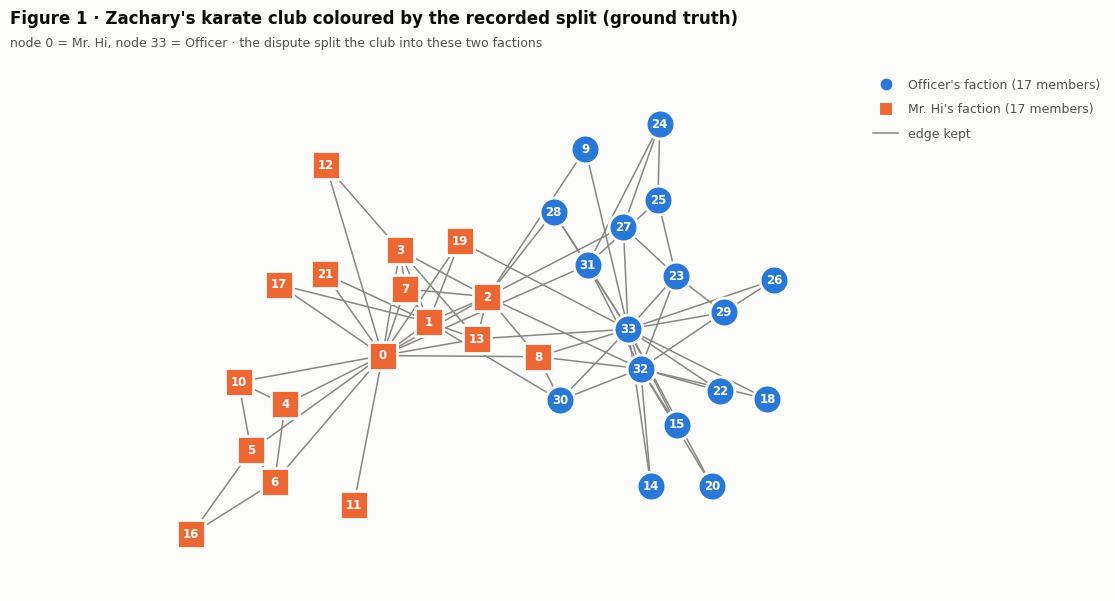

In [ ]:
# Figure 1: the network as Zachary recorded it, coloured by the two real factions (ground truth).
# Colour slots 1 and 2 are assigned so that they match the two groups of the first spectral split (Figure 2).
fig, ax = plt.subplots(figsize=(9.6, 6.8))
truth = {v: 2 if faction[v] == "Mr. Hi" else 1 for v in nodes}
draw_network(ax, truth, {2: f"Mr. Hi's faction ({len(mr_hi)} members)", 1: f"Officer's faction ({len(officer)} members)"})
figure_header(fig, "Figure 1 · Zachary's karate club coloured by the recorded split (ground truth)",
              "node 0 = Mr. Hi, node 33 = Officer · the dispute split the club into these two factions")
save_fig(fig, "fig01_zachary_factions.png")
plt.show()

## 4. Construction of the modularity matrix — **[Handout §3.1]**
We build the adjacency matrix, the degree vector and the global modularity matrix $B=A-\mathbf k\mathbf k^\top/2m$ once. Every restricted matrix $B^{(C)}$ used later is cut out of this one matrix. Each property claimed in Section 2.2 is checked numerically.

In [ ]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)    # adjacency matrix, entries in {0, 1}
k = A.sum(axis=1)                                        # degree vector, k_i = sum_j A_ij
two_m = k.sum()                                          # total degree = 2m
B = A - np.outer(k, k) / two_m                           # modularity matrix  B = A - k k^T / (2m)
ones = np.ones(n)

with np.printoptions(precision=2, suppress=True, linewidth=120):
    print("Degree vector k (first 12 nodes):", k[:12].astype(int))
    print("\nTop-left 5 x 5 block of B:")
    print(B[:5, :5])

print()
check(A.shape == (n, n) and B.shape == (n, n) and k.shape == (n,), "Dimensions: A and B are n x n, k has length n", f"n = {n}")
check(set(np.unique(A)) == {0.0, 1.0}, "A is a 0/1 matrix (edge weights ignored)")
check(np.array_equal(A, A.T) and not np.diag(A).any(), "A is symmetric with a zero diagonal (undirected graph, no self-loops)")
check(two_m == 2 * m, "The degrees add up to 2m", f"sum of k = {two_m:.0f} = 2 x {m}")
check(np.array_equal(k, [G.degree(v) for v in nodes]), "The degree vector agrees with NetworkX degrees")
check(np.allclose(B, B.T, atol=1e-15), "B is symmetric (Proposition 1)", f"max |B - B^T| = {np.abs(B - B.T).max():.1e}")
check(np.allclose(B @ ones, 0, atol=1e-12), "B 1 = 0, every row of B sums to zero (Proposition 2)", f"max |B 1| = {np.abs(B @ ones).max():.1e}")

Degree vector k (first 12 nodes): [16  9 10  6  3  4  4  4  5  2  3  1]

Top-left 5 x 5 block of B:
[[-1.64  0.08 -0.03  0.38  0.69]
 [ 0.08 -0.52  0.42  0.65 -0.17]
 [-0.03  0.42 -0.64  0.62 -0.19]
 [ 0.38  0.65  0.62 -0.23 -0.12]
 [ 0.69 -0.17 -0.19 -0.12 -0.06]]

[PASS] Dimensions: A and B are n x n, k has length n  (n = 34)
[PASS] A is a 0/1 matrix (edge weights ignored)
[PASS] A is symmetric with a zero diagonal (undirected graph, no self-loops)
[PASS] The degrees add up to 2m  (sum of k = 156 = 2 x 78)
[PASS] The degree vector agrees with NetworkX degrees
[PASS] B is symmetric (Proposition 1)  (max |B - B^T| = 0.0e+00)
[PASS] B 1 = 0, every row of B sums to zero (Proposition 2)  (max |B 1| = 8.9e-16)


### 4.1 Eigen-decomposition of the global $B$
`numpy.linalg.eigh` is the solver for real symmetric matrices: it returns real eigenvalues in ascending order and orthonormal eigenvectors (the columns of `U`), so the leading eigenpair is the **last** one.

In [ ]:
eigvals_B, U_B = np.linalg.eigh(B)
print(f"Largest eigenvalues of B : {np.round(eigvals_B[::-1][:4], 4)}")
print(f"Smallest eigenvalues of B: {np.round(eigvals_B[:3], 4)}   ({(eigvals_B > 1e-10).sum()} positive, {(eigvals_B < -1e-10).sum()} negative)\n")

null = np.flatnonzero(np.abs(eigvals_B) < 1e-10)         # eigenvectors belonging to the eigenvalue 0
check(np.allclose(B @ U_B, U_B * eigvals_B, atol=1e-10), "Eigen-equation B u = lambda u holds for all n eigenpairs", f"max residual = {np.abs(B @ U_B - U_B * eigvals_B).max():.1e}")
check(np.allclose(U_B.T @ U_B, np.eye(n), atol=1e-10), "The eigenvectors are orthonormal (Theorem 1)")
check(len(null) >= 1, "B has the eigenvalue 0 (Proposition 2)", f"smallest |lambda| = {np.abs(eigvals_B).min():.1e}")
check(abs(np.linalg.norm(U_B[:, null].T @ (ones / np.sqrt(n))) - 1) < 1e-8, "The all-ones vector lies in the eigenspace of the eigenvalue 0 (projection has norm 1)")

by_neighbourhood = {}
for v in nodes:
    by_neighbourhood.setdefault(frozenset(G[v]), []).append(v)
twins = [c for c in by_neighbourhood.values() if len(c) > 1]
print(f"\nThe eigenvalue 0 has multiplicity {len(null)} here, not 1: A itself is rank-deficient (rank {np.linalg.matrix_rank(A)} < {n}); for example members")
print(f"with identical neighbourhoods ({twins}) give identical rows of A. Proposition 2 only promises that 1 lies in this eigenspace, which the last")
print("check confirms. For a repeated eigenvalue a solver returns an arbitrary orthonormal basis of the eigenspace, so no single column of U has to equal 1/sqrt(n).")

Largest eigenvalues of B : [4.9771 3.0428 2.3202 1.4888]
Smallest eigenvalues of B: [-5.5925 -3.4511 -3.1266]   (11 positive, 12 negative)

[PASS] Eigen-equation B u = lambda u holds for all n eigenpairs  (max residual = 5.6e-15)
[PASS] The eigenvectors are orthonormal (Theorem 1)
[PASS] B has the eigenvalue 0 (Proposition 2)  (smallest |lambda| = 6.3e-17)
[PASS] The all-ones vector lies in the eigenspace of the eigenvalue 0 (projection has norm 1)

The eigenvalue 0 has multiplicity 11 here, not 1: A itself is rank-deficient (rank 24 < 34); for example members
with identical neighbourhoods ([[14, 15, 18, 20, 22], [17, 21]]) give identical rows of A. Proposition 2 only promises that 1 lies in this eigenspace, which the last
check confirms. For a repeated eigenvalue a solver returns an arbitrary orthonormal basis of the eigenspace, so no single column of U has to equal 1/sqrt(n).


### 4.2 [Addition A3] An independent way to compute the modularity
To check the bookkeeping of the gains later we need a modularity function that does **not** use $B$. Counting edges directly,

$$Q=\sum_{c}\Big[\frac{L_c}{m}-\Big(\frac{K_c}{2m}\Big)^2\Big],$$

where $L_c$ is the number of edges inside community $c$ and $K_c$ is the sum of the degrees of its nodes. We compare it with the matrix formula $Q=\frac1{2m}\sum_c\mathbf 1_c^\top B\mathbf 1_c$ and with NetworkX's own `modularity`. A real partition is available for the test: Zachary's two factions.

In [ ]:
def modularity_from_edges(partition):
    """Modularity computed directly from the graph (NOT from B): Q = sum_c [ L_c/m - (K_c/2m)^2 ]."""
    Q = 0.0
    for c in partition:
        L_c = G.subgraph(c).number_of_edges()                 # edges with both ends in c
        K_c = sum(deg for _, deg in G.degree(c))              # total degree of the nodes of c
        Q += L_c / m - (K_c / two_m) ** 2
    return Q

def modularity_from_B(partition):
    """Modularity from the matrix formula Q = (1/2m) sum_c 1_c^T B 1_c."""
    return sum(B[np.ix_(c, c)].sum() for c in partition) / two_m

factions = [mr_hi, officer]
Q_edges, Q_matrix = modularity_from_edges(factions), modularity_from_B(factions)
Q_nx = nx_modularity(G, [set(c) for c in factions], weight=None)     # weight=None: unweighted, like the handout
Q_nx_weighted = nx_modularity(G, [set(c) for c in factions])         # NetworkX default: uses the edge weights

print(f"Q of Zachary's real split  edge formula: {Q_edges:.6f} | matrix formula: {Q_matrix:.6f} | networkx (weight=None): {Q_nx:.6f}")
print(f"networkx with its DEFAULT weight='weight' gives {Q_nx_weighted:.6f}: a different (weighted) quantity, so we always pass weight=None.\n")
check(abs(Q_edges - Q_matrix) < 1e-12 and abs(Q_edges - Q_nx) < 1e-12, "Edge formula, matrix formula and NetworkX (unweighted) give the same Q")
check(abs(modularity_from_edges([nodes])) < 1e-12 and abs(modularity_from_B([nodes])) < 1e-12, "The trivial partition has Q = 0 (Corollary 1)")

Q of Zachary's real split  edge formula: 0.358235 | matrix formula: 0.358235 | networkx (weight=None): 0.358235
networkx with its DEFAULT weight='weight' gives 0.391438: a different (weighted) quantity, so we always pass weight=None.

[PASS] Edge formula, matrix formula and NetworkX (unweighted) give the same Q
[PASS] The trivial partition has Q = 0 (Corollary 1)


## 5. Spectral bipartition algorithm — **[Handout §3.2–3.3]** with safeguards **[Addition A1, A2]**
`evaluate_community(C)` carries out one step of the recursion for a community $C$ (a list of node IDs):

1. cut $B^{(C)}$ out of the global $B$ (`restricted_B`), using the original $m$ and degrees;
2. compute its eigen-decomposition with `eigh` and take the leading eigenpair $(\lambda_1,\mathbf u_1)$;
3. **stop** if $\lambda_1\le0$ (handout stopping rule; `LAMBDA_TOL` only absorbs floating-point noise of order $10^{-15}$);
4. otherwise round $\mathbf u_1$ to $\mathbf s$ and form $C^+$, $C^-$;
5. compute the nominal gain $\frac1{4m}\mathbf s^\top B^{(C)}\mathbf s$ (handout) and the exact gain $(\star)$;
6. apply S1 and S2; the community is split only if both hold.

Every call also runs consistency checks (dimensions, symmetry, eigen-equation, orthonormality, reconstruction $B^{(C)}=U\Lambda U^\top$, the Rayleigh quotient of $\mathbf u_1$, the Rayleigh–Ritz bound). They run silently inside the recursion and are counted in the validation summary of Section 11.

In [ ]:
LAMBDA_TOL = 1e-10   # lambda_1 <= LAMBDA_TOL counts as "lambda_1 <= 0" (floating-point noise is about 1e-15)
GAIN_TOL = 1e-12     # a split must gain more than this to be accepted
SIGN_TOL = 1e-8      # eigenvector entries smaller than this are not used to fix the sign of u_1

def restricted_B(C):
    """B^(C): the rows/columns of the GLOBAL modularity matrix that belong to the nodes in C.
    It uses the m and the degrees of the whole graph; it is NOT recomputed from the induced subgraph."""
    return B[np.ix_(C, C)]

def evaluate_community(C):
    """Apply the handout's spectral test to the community C (a list of node IDs) and describe what happens."""
    C = sorted(C)
    size = len(C)
    B_C = restricted_B(C)
    one = np.ones(size)

    # eigen-decomposition of a real symmetric matrix; eigenvalues ascending, so the leading pair is the last one
    spectrum, U = np.linalg.eigh(B_C)
    lam1, u1 = spectrum[-1], U[:, -1].copy()

    check(B_C.shape == (size, size) and u1.shape == (size,), "Dimensions: B(C) is |C| x |C| and u1 has length |C|", show=False)
    check(np.allclose(B_C, B_C.T, atol=1e-12), "The restricted matrix B(C) is symmetric", show=False)
    check(np.linalg.norm(B_C @ u1 - lam1 * u1) < 1e-9, "Eigen-equation B(C) u1 = lambda1 u1 holds (residual < 1e-9)", show=False)
    check(abs(np.linalg.norm(u1) - 1) < 1e-12, "u1 has unit length", show=False)
    check(np.allclose(U.T @ U, np.eye(size), atol=1e-10), "The eigenvectors of B(C) are orthonormal", show=False)
    check(np.allclose(U @ np.diag(spectrum) @ U.T, B_C, atol=1e-10), "B(C) = U diag(lambda) U^T (spectral decomposition reproduces the matrix)", show=False)
    check(lam1 == spectrum.max() and abs(u1 @ B_C @ u1 - lam1) < 1e-9, "lambda1 is the largest eigenvalue and the Rayleigh quotient of u1 equals it", show=False)

    info = {"community": C, "size": size, "lam1": lam1, "bound": lam1 * size,
            "gap": lam1 - spectrum[-2] if size > 1 else np.inf,
            "C_plus": None, "C_minus": None, "u_min": None, "u_max": None, "min_abs_u": None,
            "sBs": np.nan, "nominal_gain": np.nan, "exact_gain": np.nan}

    # (handout) stopping rule: lambda_1 <= 0  ->  C is indivisible
    if lam1 <= LAMBDA_TOL:
        info.update(decision="stop", reason="lambda1 <= 0 (handout rule)")
        return info

    # eigenvectors are defined only up to sign: make the first non-negligible entry positive (names C+ and C- reproducibly)
    first = np.flatnonzero(np.abs(u1) > SIGN_TOL)[0]
    if u1[first] < 0:
        u1 = -u1
    s = np.where(u1 > 0, 1, -1)                                  # sign rounding exactly as in the handout
    C_plus = [v for v, si in zip(C, s) if si == 1]
    C_minus = [v for v, si in zip(C, s) if si == -1]

    sBs = s @ B_C @ s
    info.update(C_plus=C_plus, C_minus=C_minus, u_min=u1.min(), u_max=u1.max(), min_abs_u=np.abs(u1).min(), sBs=sBs,
                nominal_gain=sBs / (4 * m),                               # handout: (1/4m) s^T B^(C) s
                exact_gain=(sBs - one @ B_C @ one) / (4 * m))             # exact gain, equation (star)
    check(sBs <= lam1 * size + 1e-9, "Rayleigh-Ritz bound s^T B(C) s <= lambda1 |C| holds for the rounded vector", show=False)
    check(info["gap"] > 1e-8, "The leading eigenvalue is simple (gap to lambda2 > 1e-8), so u1 is unique up to sign", show=False)

    if not C_plus or not C_minus:                                # S1: one-sided sign pattern -> no bipartition
        info.update(decision="stop", reason="S1: all entries of u1 have the same sign")
    elif info["exact_gain"] <= GAIN_TOL:                         # S2: rounding destroyed the gain
        info.update(decision="stop", reason="S2: exact gain <= 0 after rounding")
    else:
        check(info["min_abs_u"] > 1e-6, "Accepted split: no entry of u1 is so close to 0 that its sign is numerically fragile", show=False)
        info.update(decision="split", reason="lambda1 > 0 and exact gain > 0")
    return info

### 5.1 First split: the whole graph, $C=V$
For $C=V$ the restricted matrix is the global $B$, and since $\mathbf 1^\top B\mathbf 1=0$ the nominal and the exact gain must coincide. We also compare the split with Zachary's recorded factions and look at the one member the method puts on the other side.

In [ ]:
first_split = evaluate_community(nodes)
s_first = np.array([1 if v in first_split["C_plus"] else -1 for v in nodes])
Q_first = modularity_from_edges([first_split["C_plus"], first_split["C_minus"]])

print(f"lambda_1 = {first_split['lam1']:.6f} > 0, so V can be split (gap to lambda_2: {first_split['gap']:.4f})")
print(f"C+ ({len(first_split['C_plus'])} nodes) = {first_split['C_plus']}")
print(f"C- ({len(first_split['C_minus'])} nodes) = {first_split['C_minus']}")
print(f"smallest |u1| entry = {first_split['min_abs_u']:.4f}  (far from zero, so the signs are numerically reliable)")
print(f"s^T B s = {first_split['sBs']:.4f} <= lambda_1 n = {first_split['bound']:.4f}   (Rayleigh-Ritz: rounding costs part of the relaxed optimum)")
print(f"nominal gain = {first_split['nominal_gain']:.6f} | exact gain = {first_split['exact_gain']:.6f} | Q of the split (edge formula) = {Q_first:.6f}\n")

check(abs(first_split["nominal_gain"] - first_split["exact_gain"]) < 1e-12, "For C = V the handout's gain equals the exact gain (1' B 1 = 0)")
check(abs(first_split["exact_gain"] - Q_first) < 1e-12, "For C = V the gain equals the independently computed modularity of the bipartition")

wrong = [v for v in first_split["C_plus"] if faction[v] != "Mr. Hi"] + [v for v in first_split["C_minus"] if faction[v] != "Officer"]
print(f"\nAgreement with Zachary's real factions: {n - len(wrong)} of {n} members; differing member(s): {wrong}")
for v in wrong:
    same = [u for u in sorted(G[v]) if faction[u] == faction[v]]
    other = [u for u in sorted(G[v]) if faction[u] != faction[v]]
    print(f"Node {v} was recorded in the '{faction[v]}' faction, but {len(other)} of its {len(G[v])} neighbours {other} "
          f"belong to the other faction and only {len(same)} {same} to its own, so the graph alone points to the other side.")
print(f"Q of Zachary's real split = {Q_edges:.4f}; Q of the spectral split = {Q_first:.4f}")

lambda_1 = 4.977080 > 0, so V can be split (gap to lambda_2: 1.9343)
C+ (16 nodes) = [0, 1, 2, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21]
C- (18 nodes) = [8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33]
smallest |u1| entry = 0.0479  (far from zero, so the signs are numerically reliable)
s^T B s = 115.8974 <= lambda_1 n = 169.2207   (Rayleigh-Ritz: rounding costs part of the relaxed optimum)
nominal gain = 0.371466 | exact gain = 0.371466 | Q of the split (edge formula) = 0.371466

[PASS] For C = V the handout's gain equals the exact gain (1' B 1 = 0)
[PASS] For C = V the gain equals the independently computed modularity of the bipartition

Agreement with Zachary's real factions: 33 of 34 members; differing member(s): [8]
Node 8 was recorded in the 'Mr. Hi' faction, but 3 of its 5 neighbours [30, 32, 33] belong to the other faction and only 2 [0, 2] to its own, so the graph alone points to the other side.
Q of Zachary's real split = 0.3582; Q of the spectral sp

## 6. Recursive community detection —
The recursion keeps a **queue** of communities that still have to be tested. It starts with the whole vertex set $V$. In every round the oldest community is taken from the queue and passed to `evaluate_community`; if it is split, both parts go to the back of the queue, otherwise it is final. Testing the communities in this (breadth-first) order only influences the *numbering of the iterations*: the test of a community depends on its own members alone, so any other order ends with the same final communities.

**Iteration numbering.** The $t$-th accepted split is iteration $t$ (`splits[t-1]` in the code). Attempts that are *not* accepted (a community that is found indivisible) are not iterations; they are listed separately in Section 6.2.

In [ ]:
queue = deque([list(nodes)])      # communities that still have to be tested; start with the whole vertex set V
splits = []                       # accepted splits in the order in which they happen: splits[t-1] is iteration t
final_communities = []            # communities that could not be split any further
not_split = []                    # the test records of those communities (for the table in Section 6.2)

while queue:
    C = queue.popleft()           # breadth-first: the oldest waiting community is tested first
    info = evaluate_community(C)
    if info["decision"] == "split":
        splits.append(info)
        queue.append(info["C_plus"])
        queue.append(info["C_minus"])
    else:
        final_communities.append(info["community"])
        not_split.append(info)

T = len(splits)                   # number of accepted splits = last iteration
print(f"{T} splits accepted -> {len(final_communities)} communities; {len(not_split)} communities were tested and left unsplit.")

4 splits accepted -> 5 communities; 5 communities were tested and left unsplit.


### 6.1 Bookkeeping and validation of the recursion — **[Addition A3]**
`history[t]` records the community number of every node after $t$ accepted splits. These numbers are also the colour numbers of the figures. **Rule:** the larger child keeps the number (and colour) of its parent and the smaller child receives the next unused number (a tie goes to $C^-$). In this way as few nodes as possible change colour from one figure to the next. `cuts[t-1]` holds the edges between $C^+$ and $C^-$ of split $t$ (the edges that are removed before the metrics of iteration $t$ are computed).

The checks below confirm that the recursion produces a valid partition, and that the gains of the individual splits add up to the independently computed modularity of the final partition.

In [ ]:
def assign_colour_slots(splits):
    """history[t][v] = community number (= colour slot) of node v after t accepted splits.
    The larger child keeps its parent's number, the smaller child gets the next unused one (a tie goes to C-)."""
    label = {v: 1 for v in nodes}
    history = [dict(label)]
    next_number = 2
    for info in splits:
        smaller = info["C_minus"] if len(info["C_minus"]) <= len(info["C_plus"]) else info["C_plus"]
        for v in smaller:
            label[v] = next_number
        next_number += 1
        history.append(dict(label))
    return history

history = assign_colour_slots(splits)

def partition_at(t):
    """The partition after t accepted splits as a list of communities; entry c-1 is community number c."""
    return [[v for v in nodes if history[t][v] == c] for c in sorted(set(history[t].values()))]

cuts = [list(nx.edge_boundary(G, info["C_plus"], info["C_minus"])) for info in splits]   # edges cut by each split
final_partition = partition_at(T)

# ---- validation ---------------------------------------------------------------------------------------
check(max(history[T].values()) <= len(COMMUNITY_STYLE), "There are enough distinct colours/markers for all communities", f"{len(final_partition)} communities")
for t, info in enumerate(splits, start=1):
    C, Cp, Cm = info["community"], info["C_plus"], info["C_minus"]
    check(len(Cp) > 0 and len(Cm) > 0, "Every accepted split produces two non-empty groups", show=False)
    check(not set(Cp) & set(Cm) and sorted(Cp + Cm) == C, "Every accepted split is a partition of the split community (disjoint groups, nothing lost)", show=False)
print(f"[PASS] All {T} accepted splits give two non-empty, disjoint groups that together make up the split community")

members_final = [v for c in final_communities for v in c]
check(all(len(c) > 0 for c in final_communities), "All final communities are non-empty")
check(len(members_final) == len(set(members_final)), "No vertex appears twice in the final communities (no duplicate assignment)")
check(sorted(members_final) == nodes, "Every one of the 34 vertices appears in exactly one final community")
check(sorted(map(sorted, final_communities)) == sorted(map(sorted, final_partition)), "The queue result agrees with the community numbers kept in `history`")

Q_after = [modularity_from_edges(partition_at(t)) for t in range(T + 1)]         # independent: edge counting, not B
check(abs(Q_after[0]) < 1e-12, "Q = 0 before the first split (trivial partition)")
for t, info in enumerate(splits, start=1):
    Q_C = modularity_from_edges([info["community"]])                              # contribution of the split community
    check(abs((Q_after[t] - Q_after[t - 1]) - info["exact_gain"]) < 1e-12, "The exact gain of each split equals the change of the independently computed Q", show=False)
    check(abs((info["nominal_gain"] - info["exact_gain"]) - Q_C / 2) < 1e-12, "Nominal gain minus exact gain equals Q_C / 2, the term the handout leaves out", show=False)
print(f"[PASS] For all {T} splits: exact gain = change of the independently computed Q, and nominal gain - exact gain = Q_C / 2")
check(abs(sum(info["exact_gain"] for info in splits) - Q_after[T]) < 1e-12, "The sum of the exact gains equals the final modularity")
Q_final = Q_after[T]
check(abs(Q_final - modularity_from_B(final_partition)) < 1e-12 and
      abs(Q_final - nx_modularity(G, [set(c) for c in final_partition], weight=None)) < 1e-12,
      "Final Q agrees across edge formula, matrix formula and NetworkX (unweighted)", f"Q = {Q_final:.6f}")

[PASS] There are enough distinct colours/markers for all communities  (5 communities)
[PASS] All 4 accepted splits give two non-empty, disjoint groups that together make up the split community
[PASS] All final communities are non-empty
[PASS] No vertex appears twice in the final communities (no duplicate assignment)
[PASS] Every one of the 34 vertices appears in exactly one final community
[PASS] The queue result agrees with the community numbers kept in `history`
[PASS] Q = 0 before the first split (trivial partition)
[PASS] For all 4 splits: exact gain = change of the independently computed Q, and nominal gain - exact gain = Q_C / 2
[PASS] The sum of the exact gains equals the final modularity
[PASS] Final Q agrees across edge formula, matrix formula and NetworkX (unweighted)  (Q = 0.409435)


### 6.2 Results of the recursion
**Accepted splits.** Besides the two gains the table shows the Rayleigh–Ritz bound $\lambda_1|C|$ and the value $\mathbf s^\top B^{(C)}\mathbf s$ actually reached by the rounded vector.

In [ ]:
print("Accepted splits (iteration t = number of splits so far)\n")
print(f"{'t':>2} {'|C|':>4} {'|C+|':>5} {'|C-|':>5} {'lambda1':>9} {'lam1*|C|':>9} {'s^T B(C) s':>11} {'nominal dQ':>11} {'exact dQ':>9} {'Q after':>8}")
for t, info in enumerate(splits, start=1):
    print(f"{t:>2} {info['size']:>4} {len(info['C_plus']):>5} {len(info['C_minus']):>5} {info['lam1']:>9.4f} {info['bound']:>9.3f} "
          f"{info['sBs']:>11.3f} {info['nominal_gain']:>11.4f} {info['exact_gain']:>9.4f} {Q_after[t]:>8.4f}")
nominal_total = sum(info["nominal_gain"] for info in splits)
print(f"\nAdding up the handout's nominal gains would give Q = {nominal_total:.4f}, but the modularity of the final partition is {Q_final:.4f} "
      f"(edge formula, matrix formula and NetworkX agree).\nThe nominal gain is exact only for t = 1; the exact gains add up correctly.")

print("\n\nCommunities that were tested but NOT split\n")
print(f"{'|C|':>4} {'lambda1':>9} {'range of u1':>14} {'nominal dQ':>11} {'exact dQ':>9}   reason")
for info in not_split:
    rng = f"{info['u_min']:.3f}..{info['u_max']:.3f}" if info["u_min"] is not None else "-"
    nom = f"{info['nominal_gain']:.4f}" if info["C_plus"] is not None else "-"
    ex = f"{info['exact_gain']:.4f}" if info["C_plus"] is not None else "-"
    print(f"{info['size']:>4} {info['lam1']:>9.4f} {rng:>14} {nom:>11} {ex:>9}   {info['reason']}")
n_lam = sum(info["reason"].startswith("lambda1") for info in not_split)
n_s1 = sum(info["reason"].startswith("S1") for info in not_split)
n_s2 = sum(info["reason"].startswith("S2") for info in not_split)
print(f"\nThe recursion stopped because lambda1 <= 0 for {n_lam} {'community' if n_lam == 1 else 'communities'}, because of safeguard S1 for {n_s1} and because of safeguard S2 for {n_s2}.")

print("\n\nFinal communities (community number = colour number in the figures)\n")
for c, members in enumerate(final_partition, start=1):
    print(f"Community {c} ({len(members):>2} node{'s' if len(members) != 1 else ' '}): {members}")
print(f"\nNumber of communities: {len(final_partition)} | modularity Q = {Q_final:.4f}")

Accepted splits (iteration t = number of splits so far)

 t  |C|  |C+|  |C-|   lambda1  lam1*|C|  s^T B(C) s  nominal dQ  exact dQ  Q after
 1   34    16    18    4.9771   169.221     115.897      0.3715    0.3715   0.3715
 2   16    10     6    2.9441    47.106      34.692      0.1112    0.0183   0.3898
 3   18    13     5    2.5041    45.074      34.692      0.1112    0.0183   0.4081
 4    6     5     1    2.1480    12.888      10.558      0.0338    0.0013   0.4094

Adding up the handout's nominal gains would give Q = 0.6277, but the modularity of the final partition is 0.4094 (edge formula, matrix formula and NetworkX agree).
The nominal gain is exact only for t = 1; the exact gains add up correctly.


Communities that were tested but NOT split

 |C|   lambda1    range of u1  nominal dQ  exact dQ   reason
  10    2.5712   0.145..0.473      0.0695    0.0000   S1: all entries of u1 have the same sign
  13    2.3563   0.051..0.485      0.0774    0.0000   S1: all entries of u1 have the 

### 6.3 A positive eigenvalue is not the same as a modularity gain
The tables above answer the question of how $\lambda_1>0$ relates to the gain that is actually obtained after rounding.
1. **Rounding costs part of the relaxed optimum.** By Rayleigh–Ritz, $\mathbf s^\top B^{(C)}\mathbf s\le\lambda_1|C|$. The rounded vectors reach between 68 % and 82 % of this bound (first split: 115.9 of 169.2).
2. **The handout's gain is exact only for $t=1$.** For $t=2,3,4$ the nominal gains (0.1112, 0.1112, 0.0338) are far larger than the exact gains (0.0183, 0.0183, 0.0013); the difference is $Q_C/2$, verified for every split above. Adding up the nominal gains would give $Q=0.628$, while the modularity of the final partition is $0.409$. The exact gains add up to it exactly.
3. **$\lambda_1>0$ does not guarantee a bipartition.** Four of the five communities at which the recursion stopped have $\lambda_1$ between 1.88 and 2.57, yet *all entries of $\mathbf u_1$ have the same sign* (column "range of $\mathbf u_1$"): the sign rounding returns $\mathbf s=\mathbf 1$, which is no split at all. The nominal formula would still report a "gain" for this vector, namely $Q_C/2$ (0.0695, 0.0774, 0.0246, 0.0332), whereas the exact gain is 0. Safeguard S1 prevents such an attempt from being counted as a split.
4. **Safeguard S2 was not needed for this graph.** All accepted splits have a positive exact gain (the smallest is 0.0013). S2 only protects against the general case in which rounding destroys the whole gain.
5. **The fourth split is a weak one.** Its exact gain is 0.0013 and it cuts no edge at all: node 11 has the single neighbour 0, and the edge 0–11 was already cut by split 2. Section 10 comes back to this.

## 7. Community visualizations at every split — **[Handout §4, visualization task]**
One figure per accepted split. Every figure shows the **whole** network on the same fixed layout, every currently identified community in its own colour and marker, and every node labelled with its original ID. Reading guide:
- Dashed dark edges are the edges **cut by this split**; faint grey edges were cut by earlier splits (they are exactly the edges that are removed from the working graph before the metrics of Section 8 are computed).
- A community keeps its colour until it is split. The larger child keeps the parent's colour and the smaller child gets a new one; the two communities created by a split are marked ★ in the legend.
- Figure 1 used the same two colours for Zachary's real factions, so Figure 2 can be compared with it directly.

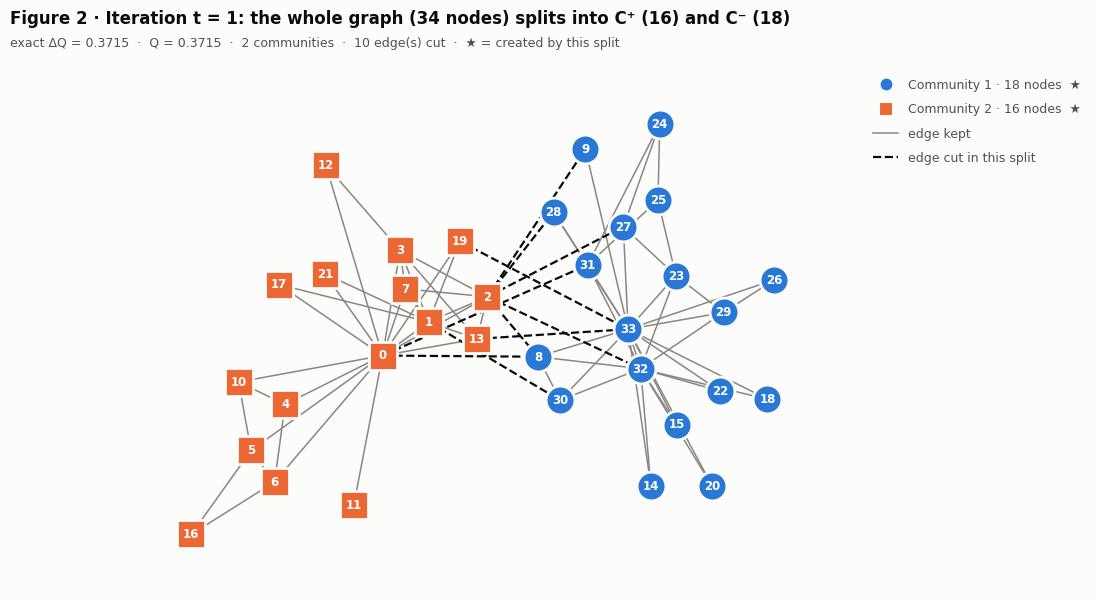

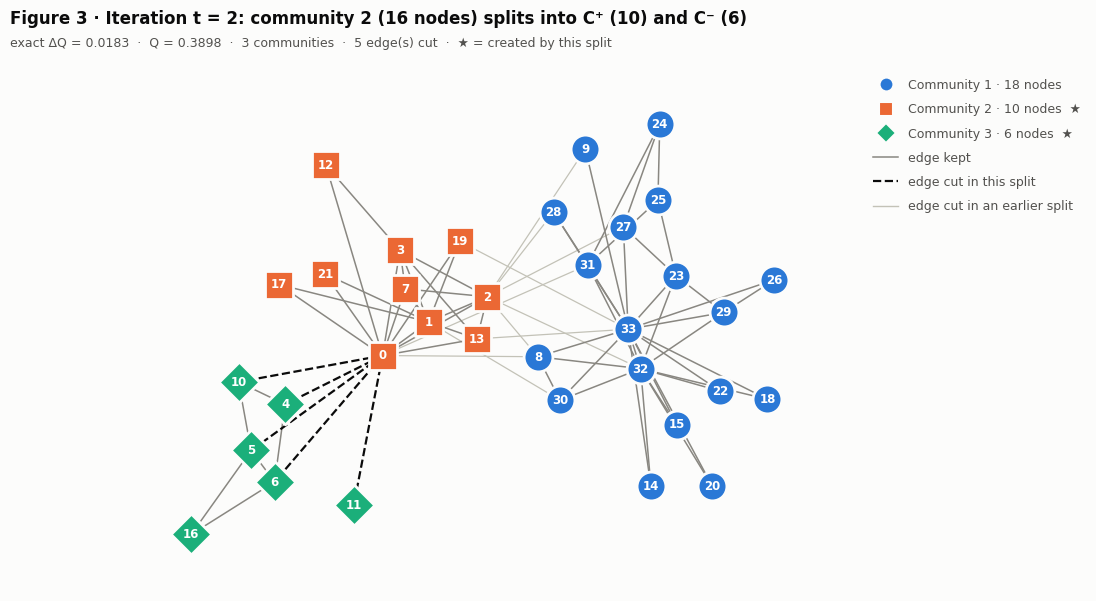

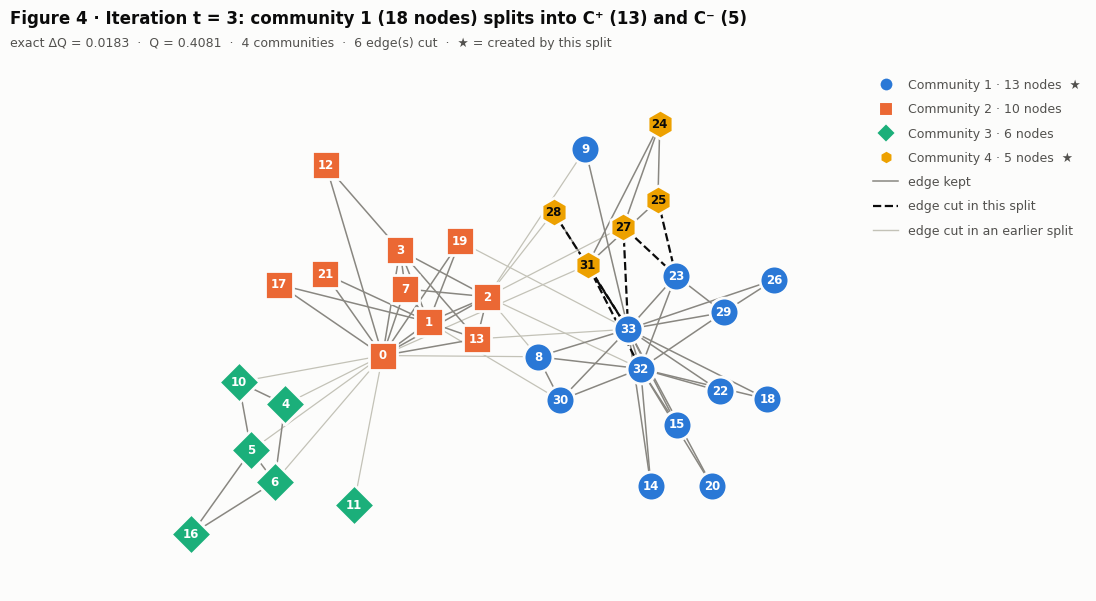

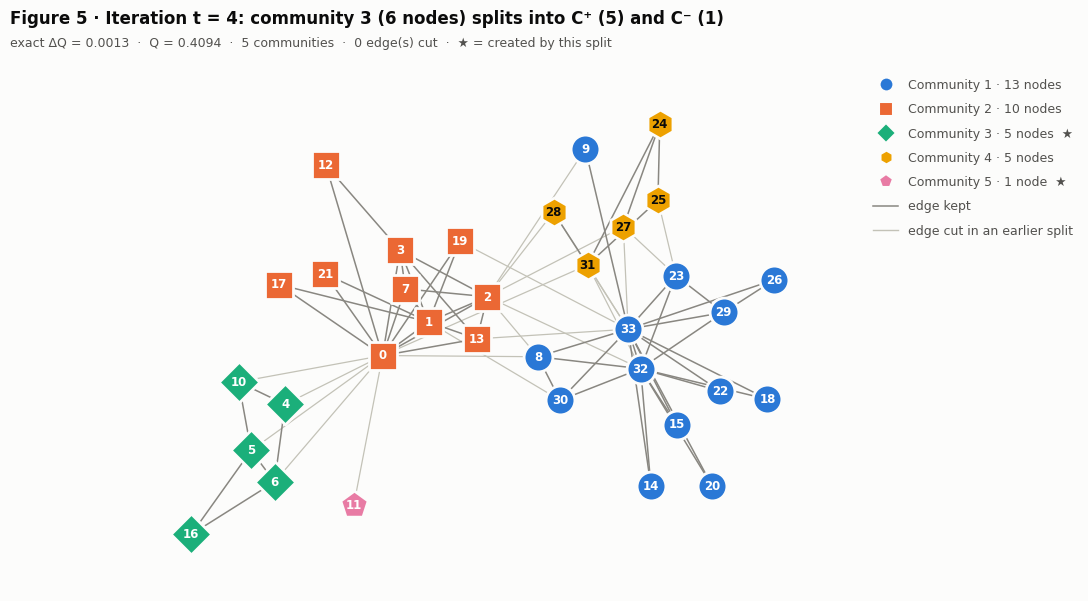

In [ ]:
def community_names(label):
    """Legend texts 'Community c · size nodes' for the communities present in `label`."""
    sizes = {}
    for v in nodes:
        sizes[label[v]] = sizes.get(label[v], 0) + 1
    return {c: f"Community {c} · {size} node{'s' if size != 1 else ''}" for c, size in sizes.items()}

for t, info in enumerate(splits, start=1):
    label = history[t]
    parent_number = history[t - 1][info["community"][0]]           # number of the community that was split
    new_number = t + 1                                             # number given to the smaller child
    names = community_names(label)
    for c in (parent_number, new_number):
        names[c] += "  ★"
    cut_earlier = [e for tt in range(t - 1) for e in cuts[tt]]

    fig, ax = plt.subplots(figsize=(9.6, 6.8))
    draw_network(ax, label, names, cut_now=cuts[t - 1], cut_before=cut_earlier)
    parent = f"the whole graph ({info['size']} nodes)" if t == 1 else f"community {parent_number} ({info['size']} nodes)"
    figure_header(fig, f"Figure {t + 1} · Iteration t = {t}: {parent} splits into C⁺ ({len(info['C_plus'])}) and C⁻ ({len(info['C_minus'])})",
                  f"exact ΔQ = {info['exact_gain']:.4f}  ·  Q = {Q_after[t]:.4f}  ·  {t + 1} communities  ·  "
                  f"{len(cuts[t - 1])} edge(s) cut  ·  ★ = created by this split")
    save_fig(fig, f"fig{t + 1:02d}_split_{t}.png")
    plt.show()

### 7.1 The final community structure
The last figure shows the final partition together with the member lists. Below it, the final communities are compared with Zachary's two recorded factions.

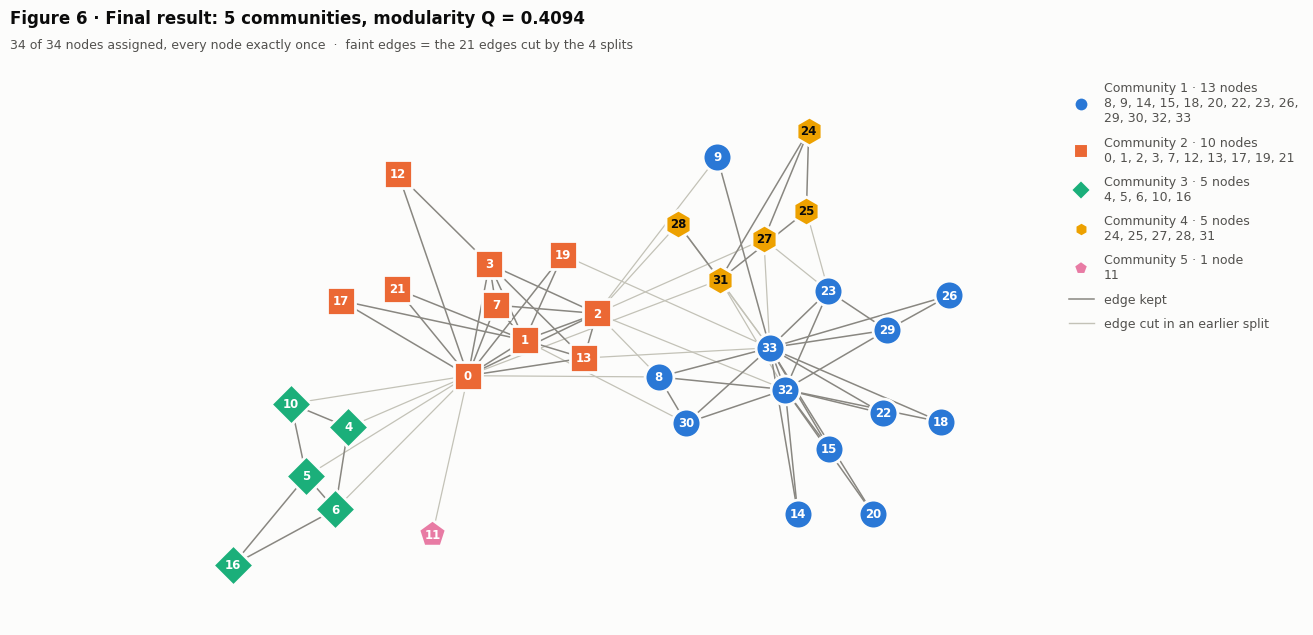

Final communities versus Zachary's recorded factions (number of members)

 community  size  Mr. Hi  Officer
         1    13       1       12
         2    10      10        0
         3     5       5        0
         4     5       0        5
         5     1       1        0


In [ ]:
names = {}
for c, members in enumerate(final_partition, start=1):
    head = f"Community {c} · {len(members)} node{'s' if len(members) != 1 else ''}"
    names[c] = head + "\n" + textwrap.fill(", ".join(map(str, members)), width=36)

fig, ax = plt.subplots(figsize=(11.8, 7.2))
draw_network(ax, history[T], names, cut_before=[e for c in cuts for e in c])
figure_header(fig, f"Figure {T + 2} · Final result: {len(final_partition)} communities, modularity Q = {Q_final:.4f}",
              f"{len(members_final)} of {n} nodes assigned, every node exactly once  ·  faint edges = the {sum(len(c) for c in cuts)} edges cut by the {T} splits")
save_fig(fig, f"fig{T + 2:02d}_final_communities.png")
plt.show()

print("Final communities versus Zachary's recorded factions (number of members)\n")
print(f"{'community':>10} {'size':>5} {'Mr. Hi':>7} {'Officer':>8}")
for c, members in enumerate(final_partition, start=1):
    print(f"{c:>10} {len(members):>5} {sum(faction[v] == 'Mr. Hi' for v in members):>7} {sum(faction[v] == 'Officer' for v in members):>8}")

## 8. Node metric calculations
After every accepted split $t$ the edges between $C^+$ and $C^-$ are removed from a **working graph** $G_t$ (`cuts[t-1]` from Section 6.1), and the four metrics are recomputed on $G_t$ with NetworkX. $G_0$ is the original graph. Because every split cuts only edges *inside* the community it divides, $G_t$ always consists of exactly the edges that lie inside the current communities. Results are stored in a dictionary keyed by the iteration number, `metrics[t][name]`, as an array in the fixed node order (entry $v$ belongs to node $v$).

In [ ]:
METRIC_NAMES = ["degree", "betweenness", "closeness", "clustering"]
METRIC_TITLES = {"degree": "Degree centrality", "betweenness": "Betweenness centrality",
                 "closeness": "Closeness centrality", "clustering": "Clustering coefficient"}

def node_metrics(H):
    """The four handout metrics of the graph H (NetworkX built-ins), as arrays in the fixed node order."""
    values = {"degree": nx.degree_centrality(H), "betweenness": nx.betweenness_centrality(H),
              "closeness": nx.closeness_centrality(H), "clustering": nx.clustering(H)}
    return {name: np.array([values[name][v] for v in nodes]) for name in METRIC_NAMES}

H = G.copy()                              # working graph: loses the cut edges after every accepted split
graphs = {0: H.copy()}                    # graphs[t] = G_t
metrics = {0: node_metrics(H)}            # iteration 0: the unsplit graph (baseline, Addition A4)
for t in range(1, T + 1):
    check(all(H.has_edge(*e) for e in cuts[t - 1]), "Every edge cut by split t is still present in the working graph (no edge is cut twice)", show=False)
    H.remove_edges_from(cuts[t - 1])
    graphs[t] = H.copy()
    metrics[t] = node_metrics(H)          # recomputed on the graph WITHOUT the cut edges

M = {name: np.array([metrics[t][name] for t in range(T + 1)]) for name in METRIC_NAMES}     # shape (T + 1, n): iteration x node
check(all(M[name].shape == (T + 1, n) for name in METRIC_NAMES), "Metric arrays have shape (iterations, nodes) in the fixed node order", f"({T + 1}, {n})")

# ---- validation of the working graphs ------------------------------------------------------------------
def inside_edges(partition):
    """The set of edges of G whose two ends lie in the same community."""
    where = {v: i for i, c in enumerate(partition) for v in c}
    return {tuple(sorted(e)) for e in G.edges if where[e[0]] == where[e[1]]}

for t in range(T + 1):
    check({tuple(sorted(e)) for e in graphs[t].edges} == inside_edges(partition_at(t)),
          "G_t contains exactly the edges of G that lie inside the current communities", show=False)
print(f"[PASS] For t = 0..{T}: G_t contains exactly the edges of G inside the current communities")
check(graphs[0].number_of_edges() == m and graphs[T].number_of_edges() == m - sum(len(c) for c in cuts), "Edge count: m minus the cut edges of all splits equals the edges left in G_T")

print("\nWorking graph G_t after each accepted split\n")
print(f"{'t':>2} {'communities':>12} {'edges cut':>10} {'edges left':>11} {'components':>11} {'isolated nodes':>15}")
for t in range(T + 1):
    isolated = [v for v in nodes if graphs[t].degree(v) == 0]
    print(f"{t:>2} {t + 1:>12} {len(cuts[t - 1]) if t else 0:>10} {graphs[t].number_of_edges():>11} "
          f"{nx.number_connected_components(graphs[t]):>11} {str(isolated) if isolated else '-':>15}")

[PASS] Metric arrays have shape (iterations, nodes) in the fixed node order  ((5, 34))
[PASS] For t = 0..4: G_t contains exactly the edges of G inside the current communities
[PASS] Edge count: m minus the cut edges of all splits equals the edges left in G_T

Working graph G_t after each accepted split

 t  communities  edges cut  edges left  components  isolated nodes
 0            1          0          78           1               -
 1            2         10          68           2               -
 2            3          5          63           4            [11]
 3            4          6          57           5            [11]
 4            5          0          57           5            [11]


### 8.1 Cross-check of the metrics against their definitions — **[Addition A3]**
The metrics are computed with NetworkX as the handout requires. Because $G_t$ is disconnected for $t\ge1$, we verify independently that NetworkX computes what Section 2.7 says it computes: `independent_metrics` evaluates the four formulas directly from breadth-first distances and shortest-path counts (no NetworkX centrality code), including the Wasserman–Faust form of closeness and the $(n-1)(n-2)/2$ normalization of betweenness.

In [ ]:
def independent_metrics(Hg):
    """The four metrics straight from their definitions, used only to cross-check NetworkX."""
    dist = dict(nx.all_pairs_shortest_path_length(Hg))              # dist[a][b] = shortest-path length (only if connected)
    sigma = {}                                                      # sigma[a][b] = number of shortest a-b paths
    for a in nodes:
        sig = {a: 1}
        for b in sorted(dist[a], key=dist[a].get):                  # nodes in increasing distance from a
            if b != a:
                sig[b] = sum(sig[u] for u in Hg[b] if dist[a][u] == dist[a][b] - 1)
        sigma[a] = sig
    out = {name: np.zeros(n) for name in METRIC_NAMES}
    for i in nodes:
        k_i = Hg.degree(i)
        out["degree"][i] = k_i / (n - 1)
        reach, total = len(dist[i]) - 1, sum(dist[i].values())      # nodes reachable from i, and the sum of their distances
        out["closeness"][i] = (reach / (n - 1)) * (reach / total) if total > 0 else 0.0
        out["clustering"][i] = 2 * nx.triangles(Hg, i) / (k_i * (k_i - 1)) if k_i >= 2 else 0.0
        passing = 0.0                                               # sum over unordered pairs {a, b} of sigma_ab(i) / sigma_ab
        for a in nodes:
            for b in nodes:
                if a < b and i != a and i != b and b in dist[a] and \
                   dist[a].get(i, np.inf) + dist[i].get(b, np.inf) == dist[a][b]:
                    passing += sigma[a][i] * sigma[i][b] / sigma[a][b]
        out["betweenness"][i] = 2 * passing / ((n - 1) * (n - 2))
    return out

worst = {name: 0.0 for name in METRIC_NAMES}
for t in range(T + 1):
    independent = independent_metrics(graphs[t])
    for name in METRIC_NAMES:
        worst[name] = max(worst[name], np.abs(independent[name] - metrics[t][name]).max())
for name in METRIC_NAMES:
    check(worst[name] < 1e-12, f"NetworkX {name} agrees with the definition-based value for every node at every iteration", f"max |difference| = {worst[name]:.1e}")

closeness_handout = np.array([(n - 1) / sum(nx.single_source_shortest_path_length(graphs[0], i).values()) for i in nodes])
check(nx.is_connected(graphs[0]) and np.allclose(closeness_handout, metrics[0]["closeness"], atol=1e-12),
      "At t = 0 the graph is connected, and NetworkX closeness equals the handout's formula (n-1) / sum_j d(i,j)")
isolated_pairs = [(t, v) for t in range(T + 1) for v in nodes if graphs[t].degree(v) == 0]
check(all(metrics[t][name][v] == 0 for t, v in isolated_pairs for name in METRIC_NAMES),
      "An isolated node has all four metrics equal to 0", f"isolated (iteration, node) pairs: {isolated_pairs}")

[PASS] NetworkX degree agrees with the definition-based value for every node at every iteration  (max |difference| = 5.6e-17)
[PASS] NetworkX betweenness agrees with the definition-based value for every node at every iteration  (max |difference| = 1.7e-16)
[PASS] NetworkX closeness agrees with the definition-based value for every node at every iteration  (max |difference| = 0.0e+00)
[PASS] NetworkX clustering agrees with the definition-based value for every node at every iteration  (max |difference| = 0.0e+00)
[PASS] At t = 0 the graph is connected, and NetworkX closeness equals the handout's formula (n-1) / sum_j d(i,j)
[PASS] An isolated node has all four metrics equal to 0  (isolated (iteration, node) pairs: [(2, 11), (3, 11), (4, 11)])


## 9. Metric evolution visualizations
One figure per metric, each with two panels that show the same numbers:
- **Left — trajectories.** One line for each of the 34 nodes across the iterations. The colour and marker of a line are those of the node's **final community**, so groups of nodes that behave alike become visible; nodes 0 (Mr. Hi) and 33 (Officer) are drawn thicker and labelled.
- **Right — heatmap with the exact values.** Rows are the nodes (every node ID is printed), columns are the iterations, and the colour bar gives the scale. The rows are grouped by final community (marker column on the left of the heatmap) and sorted by node ID inside each group.

The iteration numbering is the one defined in Section 1: $t=0$ is the original graph and $t$ is the number of accepted splits.

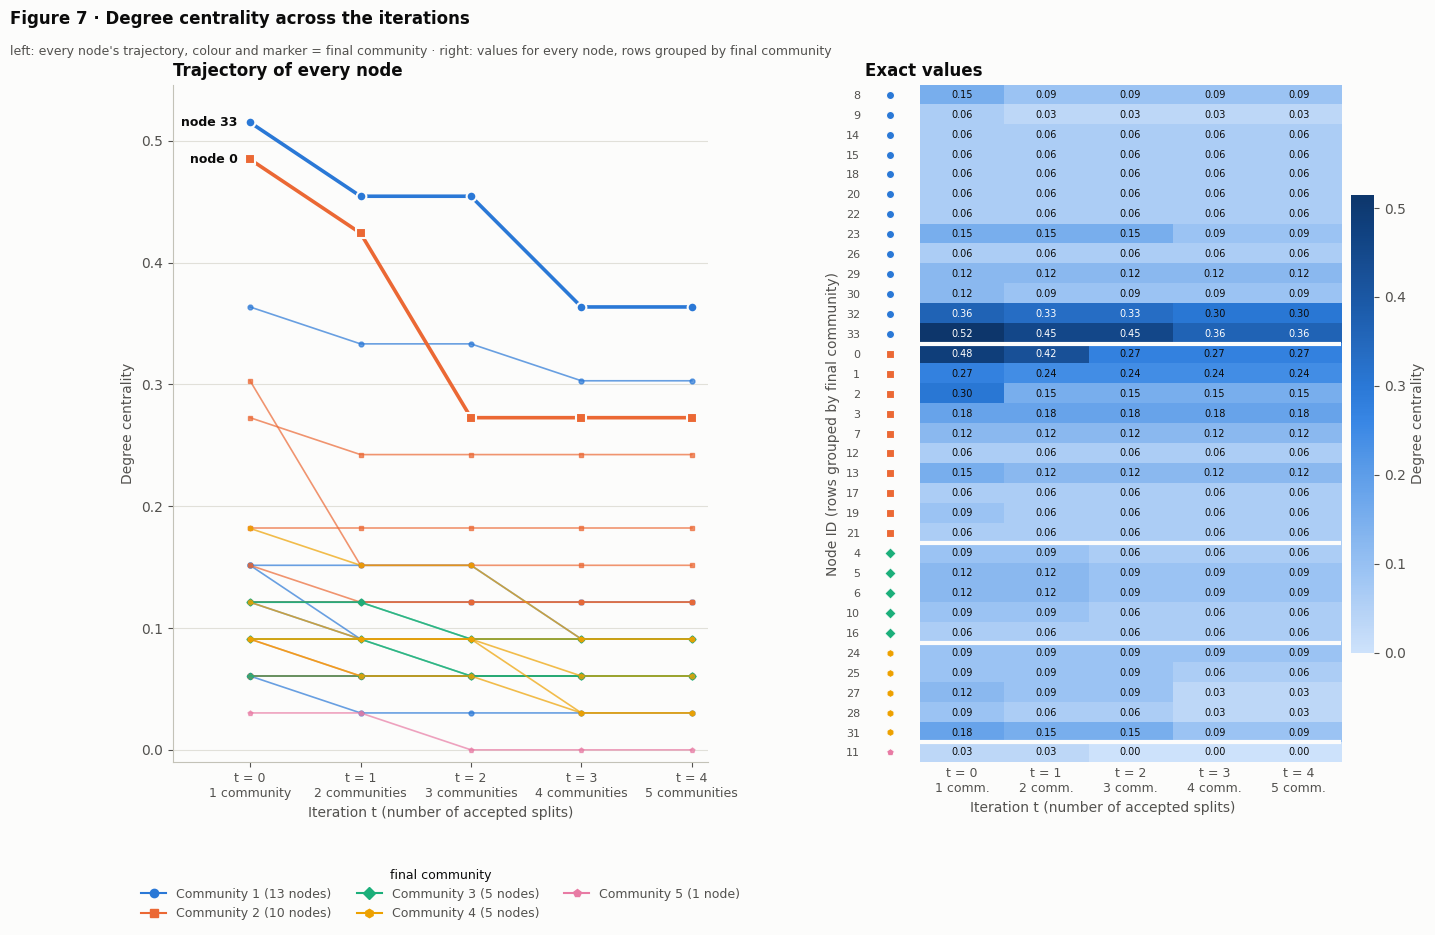

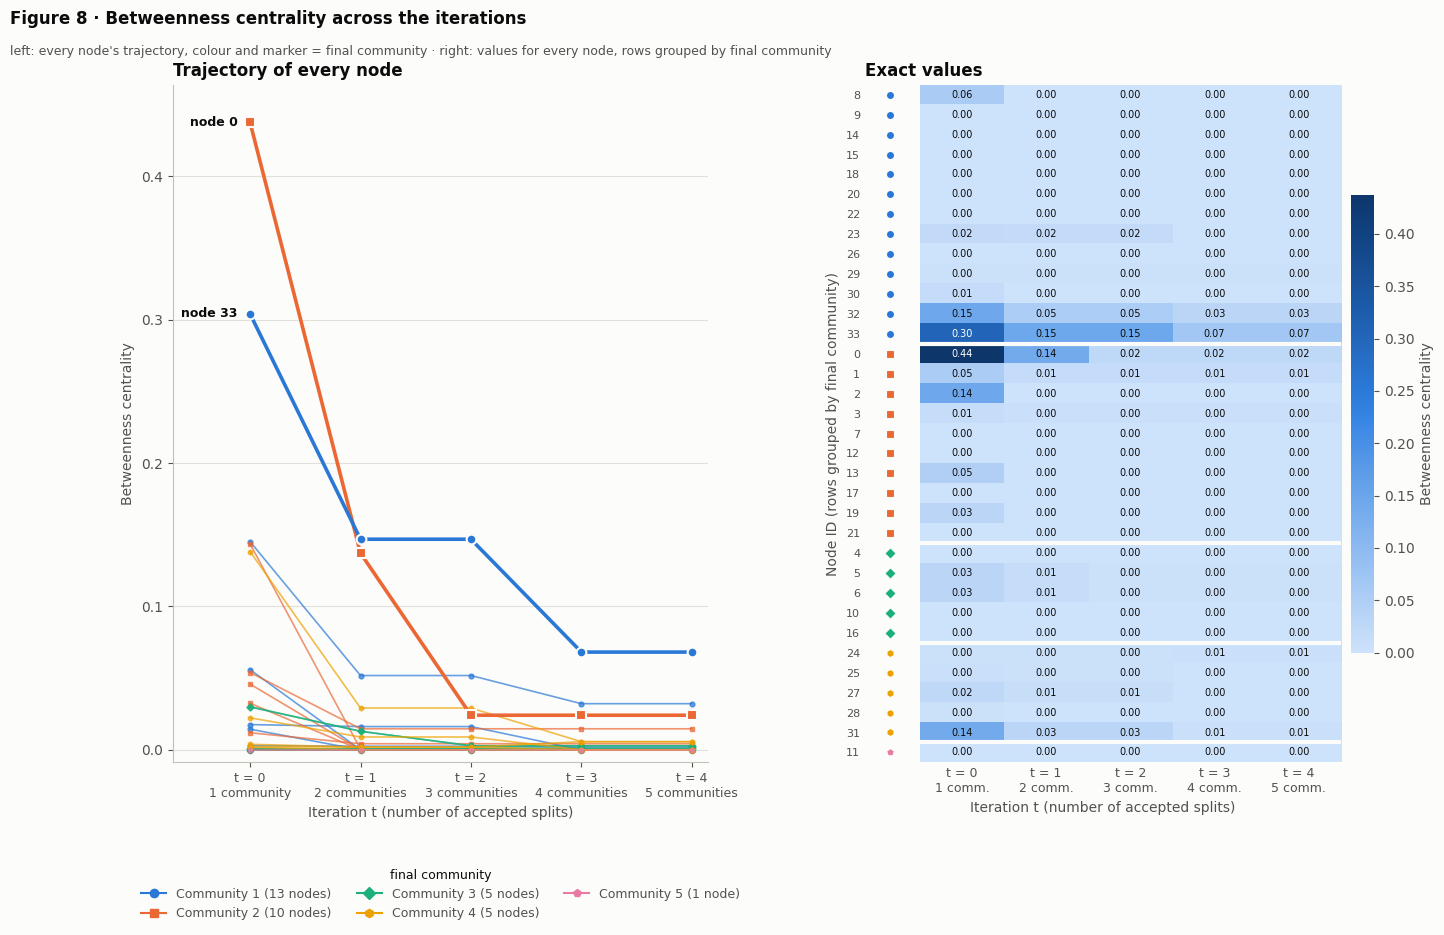

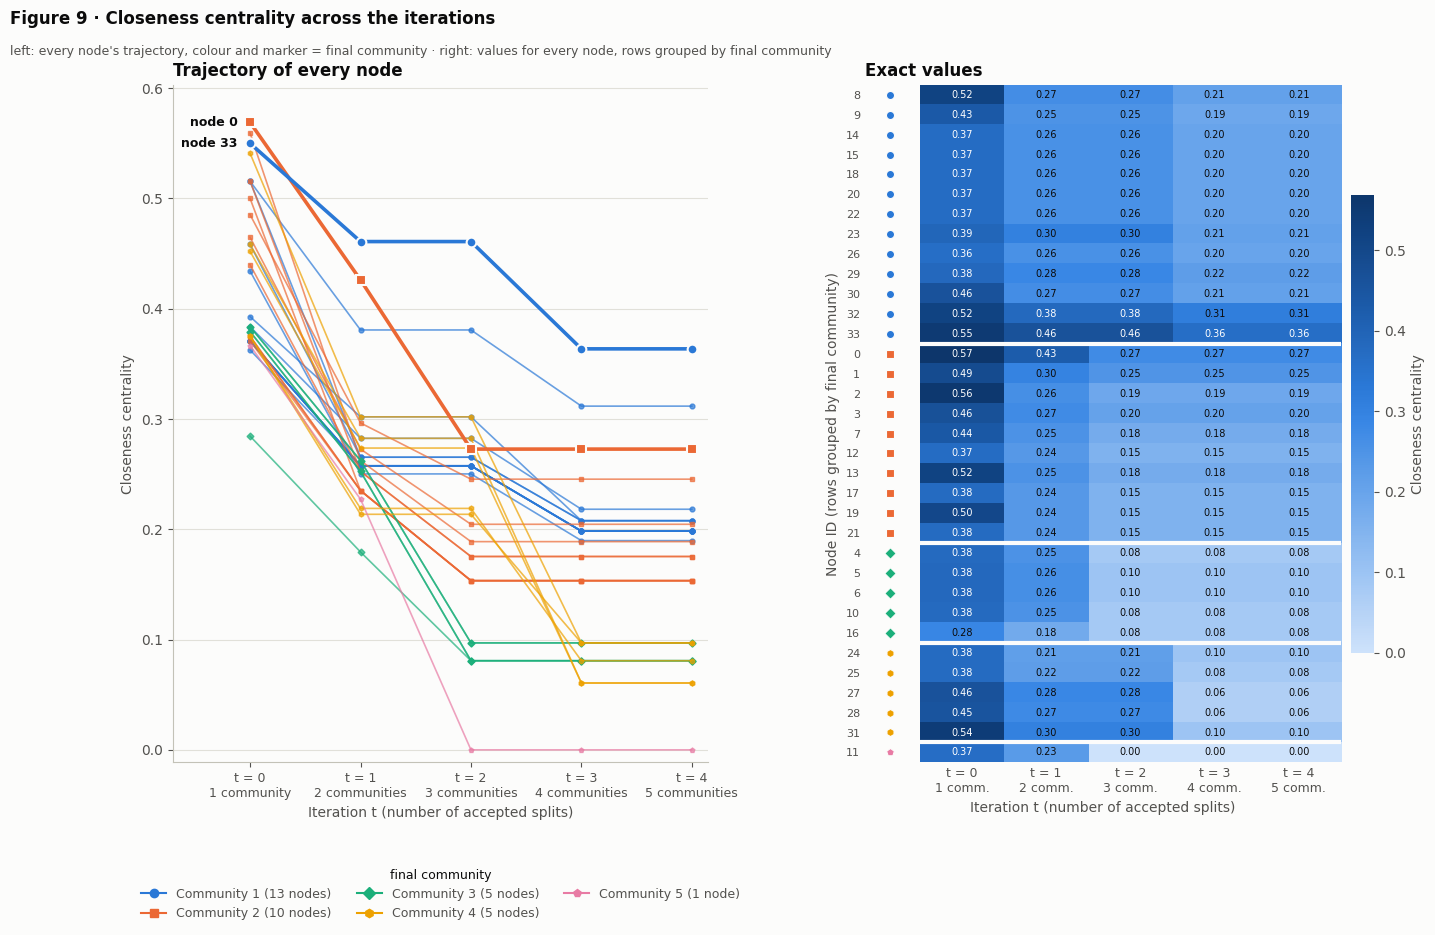

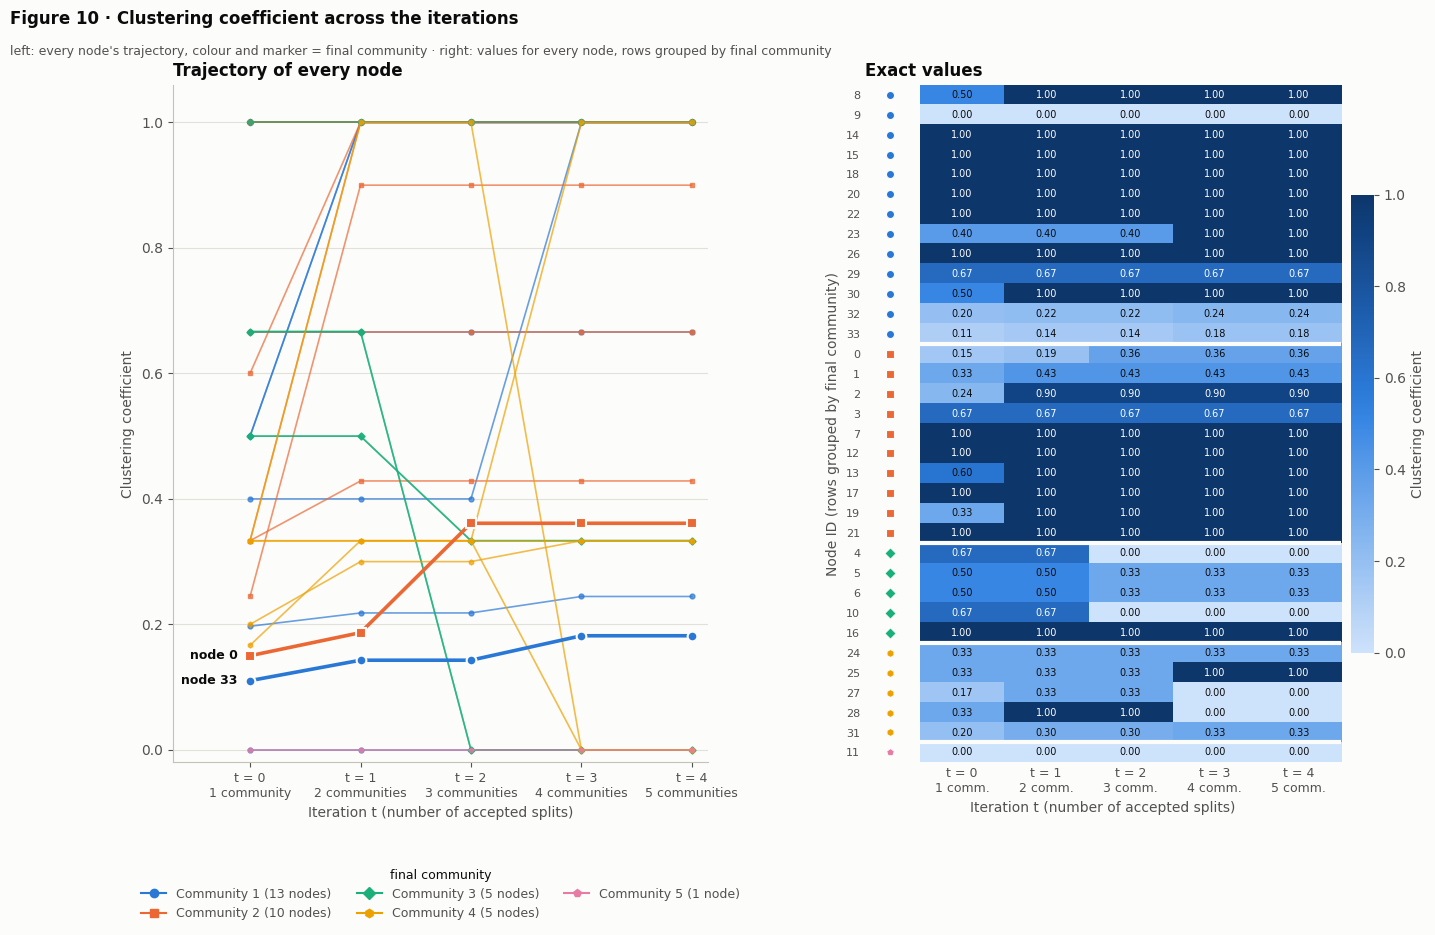

In [ ]:
final_label = history[T]
row_order = sorted(nodes, key=lambda v: (final_label[v], v))              # rows grouped by final community, then by node ID
ITER_LABELS = [f"t = {t}\n{t + 1} communit{'y' if t == 0 else 'ies'}" for t in range(T + 1)]
ITER_LABELS_SHORT = [f"t = {t}\n{t + 1} comm." for t in range(T + 1)]          # shorter version for the narrow heatmap columns

def metric_figure(name, figure_number):
    values = M[name]                                                       # shape (T + 1, n)
    title, vmax = METRIC_TITLES[name], values.max()
    x = np.arange(T + 1)
    fig, (ax_line, ax_heat) = plt.subplots(1, 2, figsize=(15.5, 8.8), gridspec_kw={"width_ratios": [1.0, 0.95], "wspace": 0.30})

    # ---- left: one trajectory per node, coloured by the node's final community -----------------------
    for v in row_order:
        colour, marker, _ = COMMUNITY_STYLE[final_label[v] - 1]
        ax_line.plot(x, values[:, v], color=colour, lw=1.2, alpha=0.7, marker=marker, ms=3.5, zorder=2)
    for v in (0, 33):                                                      # the two protagonists: thicker, labelled
        colour, marker, _ = COMMUNITY_STYLE[final_label[v] - 1]
        ax_line.plot(x, values[:, v], color=colour, lw=2.6, marker=marker, ms=7, markeredgecolor=SURFACE, markeredgewidth=1.5, zorder=3)
        ax_line.annotate(f"node {v}", (0, values[0, v]), xytext=(-9, 0), textcoords="offset points",
                         ha="right", va="center", fontsize=9, fontweight="bold", color=INK)
    ax_line.set_xlim(-0.7, T + 0.15)
    ax_line.set_ylim(-0.02 * vmax, 1.06 * vmax)
    ax_line.set_xticks(x)
    ax_line.set_xticklabels(ITER_LABELS, fontsize=9)
    ax_line.set_xlabel("Iteration t (number of accepted splits)")
    ax_line.set_ylabel(title)
    ax_line.set_title("Trajectory of every node", loc="left")
    ax_line.grid(axis="y")
    ax_line.set_axisbelow(True)
    for side in ("top", "right"):
        ax_line.spines[side].set_visible(False)
    handles = [Line2D([], [], color=COMMUNITY_STYLE[c - 1][0], marker=COMMUNITY_STYLE[c - 1][1], lw=1.5, ms=6,
                      label=f"Community {c} ({len(members)} node{'s' if len(members) != 1 else ''})")
               for c, members in enumerate(final_partition, start=1)]
    ax_line.legend(handles=handles, title="final community", loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3,
                   frameon=False, fontsize=9, title_fontsize=9, labelcolor=INK2)

    # ---- right: heatmap node x iteration with the exact values printed in the cells ---------------------
    data = values[:, row_order].T                                          # rows = nodes, columns = iterations
    image = ax_heat.imshow(data, aspect="auto", cmap=SEQ_CMAP, vmin=0, vmax=vmax, interpolation="nearest")
    ax_heat.set_xlim(-1.15, T + 0.5)                                       # room on the left for the community markers
    for i, v in enumerate(row_order):
        for j in range(T + 1):
            ax_heat.text(j, i, f"{data[i, j]:.2f}", ha="center", va="center", fontsize=7,
                         color="white" if data[i, j] > 0.6 * vmax else INK)
    for c in range(1, len(final_partition) + 1):                           # community marker column and block separators
        rows = [i for i, v in enumerate(row_order) if final_label[v] == c]
        colour, marker, _ = COMMUNITY_STYLE[c - 1]
        ax_heat.scatter(np.full(len(rows), -0.85), rows, marker=marker, s=34, color=colour, edgecolors=SURFACE, linewidths=0.8, zorder=3)
        if rows[0] > 0:
            ax_heat.axhline(rows[0] - 0.5, color=SURFACE, lw=3, zorder=2)
    ax_heat.set_xticks(x)
    ax_heat.set_xticklabels(ITER_LABELS_SHORT, fontsize=9)
    ax_heat.set_yticks(range(n))
    ax_heat.set_yticklabels([str(v) for v in row_order], fontsize=8)
    ax_heat.tick_params(length=0)
    ax_heat.set_xlabel("Iteration t (number of accepted splits)")
    ax_heat.set_ylabel("Node ID (rows grouped by final community)")
    ax_heat.set_title("Exact values", loc="left")
    for side in ax_heat.spines.values():
        side.set_visible(False)
    bar = fig.colorbar(image, ax=ax_heat, fraction=0.045, pad=0.02)
    bar.set_label(title)
    bar.outline.set_visible(False)

    figure_header(fig, f"Figure {figure_number} · {title} across the iterations",
                  "left: every node's trajectory, colour and marker = final community · right: values for every node, rows grouped by final community")
    save_fig(fig, f"fig{figure_number:02d}_{name}_evolution.png")
    plt.show()

for idx, name in enumerate(METRIC_NAMES):
    metric_figure(name, T + 3 + idx)

## 10. Results and discussion
### 10.1 The numbers behind the figures
The tables below summarize the metric arrays `M[name]` (iteration × node). They are the basis of the discussion in Section 10.2. Ties are broken in favour of the smaller node ID, and a list whose fifth place is tied with the sixth is marked. The statements of Section 10.2 do not depend on how ties are broken (this is checked in Section 10.3).

In [ ]:
def top_nodes(vec, size=5):
    """The `size` nodes with the largest value (ties: smaller node ID first)."""
    return [int(v) for v in np.argsort(-vec, kind="stable")[:size]]

print("Top-5 nodes per centrality and iteration (value in brackets)\n")
for name in ["degree", "betweenness", "closeness"]:
    print(METRIC_TITLES[name])
    for t in range(T + 1):
        ranked = np.sort(M[name][t])[::-1]
        tie = "   (5th place tied with the 6th)" if abs(ranked[4] - ranked[5]) < 1e-12 else ""
        print(f"  t = {t}:  " + ",  ".join(f"{v} ({M[name][t, v]:.3f})" for v in top_nodes(M[name][t])) + tie)
    always = sorted(set.intersection(*[set(top_nodes(M[name][t])) for t in range(T + 1)]))
    print(f"  nodes in the top 5 at EVERY iteration: {always}\n")

print("Mean over all 34 nodes\n")
print(f"{'':<24}" + "".join(f"{'t = ' + str(t):>9}" for t in range(T + 1)))
for name in METRIC_NAMES:
    print(f"{METRIC_TITLES[name]:<24}" + "".join(f"{M[name][t].mean():>9.4f}" for t in range(T + 1)))

print("\n\nLargest changes between t = 0 and t = %d (five largest absolute changes per metric)\n" % T)
for name in METRIC_NAMES:
    change = M[name][T] - M[name][0]
    print(METRIC_TITLES[name])
    for v in np.argsort(-np.abs(change), kind="stable")[:5]:
        print(f"  node {int(v):>2}: {M[name][0, v]:.3f} -> {M[name][T, v]:.3f}   (change {change[v]:+.3f})")
    print()

print("Mean metric value inside each final community, at t = 0 and at t = %d\n" % T)
print(f"{'community':>10} {'size':>5}" + "".join(f"{METRIC_TITLES[name].split()[0]:>22}" for name in METRIC_NAMES))
for c, members in enumerate(final_partition, start=1):
    cells = "".join(f"{M[name][0, members].mean():>10.3f} ->{M[name][T, members].mean():>7.3f}" for name in METRIC_NAMES)
    print(f"{c:>10} {len(members):>5}{cells}")

Top-5 nodes per centrality and iteration (value in brackets)

Degree centrality
  t = 0:  33 (0.515),  0 (0.485),  32 (0.364),  2 (0.303),  1 (0.273)
  t = 1:  33 (0.455),  0 (0.424),  32 (0.333),  1 (0.242),  3 (0.182)
  t = 2:  33 (0.455),  32 (0.333),  0 (0.273),  1 (0.242),  3 (0.182)
  t = 3:  33 (0.364),  32 (0.303),  0 (0.273),  1 (0.242),  3 (0.182)
  t = 4:  33 (0.364),  32 (0.303),  0 (0.273),  1 (0.242),  3 (0.182)
  nodes in the top 5 at EVERY iteration: [0, 1, 32, 33]

Betweenness centrality
  t = 0:  0 (0.438),  33 (0.304),  32 (0.145),  2 (0.144),  31 (0.138)
  t = 1:  33 (0.147),  0 (0.137),  32 (0.052),  31 (0.029),  23 (0.016)
  t = 2:  33 (0.147),  32 (0.052),  31 (0.029),  0 (0.024),  23 (0.016)
  t = 3:  33 (0.068),  32 (0.032),  0 (0.024),  1 (0.015),  24 (0.006)   (5th place tied with the 6th)
  t = 4:  33 (0.068),  32 (0.032),  0 (0.024),  1 (0.015),  24 (0.006)   (5th place tied with the 6th)
  nodes in the top 5 at EVERY iteration: [0, 32, 33]

Closeness centr

### 10.2 Discussion
**Setting.** The recursion produced five communities with $Q=0.4094$. The four splits cut 21 of the 78 edges, so 57 edges (73 %) stay inside communities. Twenty of the 34 nodes lose at least one edge; the other 14 keep their whole neighbourhood. All statements below refer to the tables of Section 10.1 and to Figures 7–10, and every number quoted here is verified by code in Section 10.3.

**Which nodes consistently remain central across the splits?**
- **Node 33 (the Officer)** is the clearest case. Its degree centrality is the highest at every iteration (0.515 at $t=0$, 0.364 at $t=4$); its betweenness is the highest from $t=1$ on and its closeness from $t=1$ on; and it is the *only* node that is among the five most central nodes in all three centralities at every iteration.
- **Node 32** is among the three most central nodes in all three centralities from $t=1$ on (second place from $t=2$ on), although in the original graph it only shared fifth place in closeness (with nodes 8 and 13).
- **Nodes 0 and 1** stay in the top five by degree at every iteration. **Node 0 (Mr. Hi)** is the most central node of the *original* graph by betweenness (0.438) and closeness (0.569) and second by degree (0.485), but this does not last: its degree rank slips from second to third, its betweenness falls to 0.024 and its closeness rank drops to eighth at $t=2$ before it recovers to third.

**Degree centrality: hubs lose exactly their cut edges.** Removing edges can only lower the degree, so the information lies in the *ranks*. Node 33 loses 5 of its 17 edges and node 0 loses 7 of its 16 (0.485 → 0.273). Node 2 is the example of a node that falls out of the leaders: it had degree rank 4 (0.303), but all five of its edges to the other side are cut in the first split, so it ends sixth (0.152). After the partition each hub is adjacent to *every other member of its community*: node 0 has degree 9 in a community of 10 nodes and node 33 has degree 12 in a community of 13. This is what makes them natural centres of their communities.

**Betweenness centrality: who bridges, and why the bridge disappears.** In the original graph node 0 lies on the largest share of shortest paths (0.438), followed by node 33 (0.304). After the first split node 33 leads (0.147 against 0.137), and after the second split node 0 collapses to 0.024. The reason is structural: node 0 is the **only articulation point** of the Karate Club graph, and the six nodes 4, 5, 6, 10, 11, 16 reach the rest of the network exclusively through it. As long as the edges 0–4, 0–5, 0–6, 0–10 and 0–11 exist, every shortest path from one of these six nodes to a node outside their group (other than node 0 itself) passes through node 0; split 2 cuts exactly these five edges (the dashed edges of Figure 3). Nodes 2 and 31 were strong intermediaries between the two factions (0.144 and 0.138) and drop to 0.0005 and 0.006: their brokerage was mostly *between* the communities and vanishes when the communities are pulled apart. Inside the final communities the main brokers are nodes 33 (0.068), 32 (0.032) and 0 (0.024); nodes 0, 32 and 33 are the ones that are in the top five at every iteration. The mean betweenness falls by 89 % (0.044 → 0.0048) and the number of nodes with betweenness 0 grows from 12 to 21. Betweenness shows the largest relative fall of the four metrics, so it is the one that depends most on the connections *between* communities.

**Closeness centrality: reach, and the size of the community.** Initially the most central nodes are 0 (0.569), 2 (0.559), 33 (0.550) and 31 (0.541); nodes 8, 13 and 32 tie for fifth place. After the partition a node can only reach the members of its own component. In a community of $s$ nodes the largest possible value is $(s-1)/(n-1)$, and both hubs attain exactly this bound: node 33 has $12/33=0.364$ in its 13-node community and node 0 has $9/33=0.273$ in its 10-node community, whereas the best value in each of the two 5-node communities is only 0.097 and the isolated node 11 has 0. Hence the final top five (33, 32, 0, 1, 29) consists of members of the two large communities, and the mean closeness falls by 61 % (0.427 → 0.165). The nodes that sat between the two factions lose most: nodes 31 (0.541 → 0.097), 27, 28 and 2 (0.559 → 0.189) each have neighbours in both of Zachary's factions. Closeness therefore partly measures the *size* of the community a node ends up in.

**Clustering coefficient: the one metric that rises.** Although 27 % of the edges are removed, the mean clustering coefficient *increases* from 0.571 to 0.684 after the first split and ends at 0.641 (+12 %). The number of nodes with $C=1$ grows from 11 to 17; 12 nodes increase, 6 decrease and 16 stay unchanged. The mechanism is that the removed edges are the *inter-community* edges. If the neighbours of a node were spread over two communities, the neighbour pairs across the cut were never connected and lowered $C(i)$; once the cut neighbours are gone, the remaining ones belong to one dense community. Node 2 is the extreme case (0.244 → 0.900): its five remaining neighbours 0, 1, 3, 7, 13 form 9 closed pairs out of 10. Nodes 8 and 30 (0.50 → 1.00), 19 and 25 (0.33 → 1.00) and node 13 (0.60 → 1.00) behave in the same way. The decreases show the opposite mechanism. Nodes 4 and 10 owed their coefficient of 0.667 to two triangles through node 0; cutting the edges of node 0 destroys these triangles and leaves two non-adjacent neighbours, so $C$ drops to 0. Nodes 5 and 6 fall from 0.50 to 0.33 for the same reason (two of their three triangles ran through node 0). Nodes 27 and 28 also drop to 0, but only because their degree falls to 1 and $C$ is defined as 0 for $k_i<2$: a convention, not evidence of weaker embedding.

**How does community separation influence the four metrics?**
- *Degree* is purely local: it changes only through the node's own cut edges. The 14 interior nodes keep their degree.
- *Betweenness and closeness* are global: they depend on shortest paths across the whole graph, so they change even for nodes that lose no edge. All 14 interior nodes lose closeness; three of them (nodes 3, 24 and 29) also change their betweenness, and that of node 24 even rises (0.002 → 0.006). The total betweenness of all nodes shrinks from 1.50 to 0.16 because every pair of nodes in different communities stops contributing.
- *Clustering* is local too, but it depends on the edges *between the neighbours* of a node. For the 14 interior nodes all neighbours stay in the same community, so no neighbour pair is affected and the coefficient is unchanged.
- Boundary nodes (the 20 nodes with cut edges) change most, and which metric changes depends on their role: hubs lose degree and brokerage, bridge nodes lose betweenness and closeness, nodes whose neighbours straddled a cut gain clustering.

**Which nodes change their structural importance most?** Node 0 changes most in degree (−0.212) and in betweenness (−0.413); node 33 follows in betweenness (−0.236) and, together with node 2, in degree (−0.152 each). The largest closeness losses are nodes 31 (−0.444), 27 (−0.398), 28 (−0.391), 2 (−0.371) and 11 (−0.367, to zero). The largest clustering gains are nodes 19 and 25 (+0.667) and node 2 (+0.656); the largest losses are nodes 4 and 10 (−0.667). Node 2 changes in every metric at once: it loses half of its degree, virtually all of its betweenness (0.144 → 0.0005) and two thirds of its closeness, yet its neighbourhood becomes almost a clique. Node 11 becomes completely isolated at $t=2$ (all four metrics 0) because its only neighbour is node 0 and the edge 0–11 is cut in the second split.

**Limitations of the method and of this analysis.**
1. *Greedy and rounded.* Each split rounds the sign of a relaxed solution (the first split reaches 68 % of the Rayleigh–Ritz bound) and is never revisited, so $Q=0.4094$ is the result of a heuristic and is not claimed to be maximal. A refinement step that moves single nodes between communities, which is not part of the handout, could change the result.
2. *The stopping rule is only a heuristic for the exact gain.* $\lambda_1>0$ does not guarantee a split (four communities had $\lambda_1>0$ but a one-signed eigenvector), and in general $\lambda_1\le0$ does not strictly exclude a positive exact gain (remark in Section 2.6); in this run the rule fired only once, for the singleton $\{11\}$, which cannot be split anyway. The handout's gain formula overstates the gains of later splits (0.628 against 0.409 in total).
3. *A weak last split.* Isolating node 11 gains only 0.0013 and removes no edge, so the metrics at $t=4$ equal those at $t=3$. Node 11 has degree 1 and its only neighbour (node 0) was separated from it in split 2, so it was left inside the community $\{4,5,6,10,11,16\}$ without any edge to it; split 4 merely takes it out. It is a clean-up step, not the discovery of a community.
4. *Properties of modularity.* Modularity optimization has a resolution limit (Fortunato and Barthélemy, 2007), the partitions are hard (no overlap), and the interaction counts of the data set (edge weights) are ignored, as in the handout.
5. *Structure only.* The first split disagrees with Zachary's records for node 8, who is recorded as a follower of Mr. Hi but has three neighbours in the Officer's group (30, 32, 33) and only two in his own (0, 2). A method that sees only the graph cannot know why a member chose a faction.
6. *Metrics on cut graphs.* After the cuts the metrics describe the role of a node *inside its community graph*, not in the original network. Closeness and betweenness are normalized with the size of the whole graph, so values of communities of different size are not comparable, and the clustering coefficient is 0 by convention for $k_i<2$.
7. *One small data set.* All conclusions concern the Karate Club graph and do not claim to be general.

### 10.3 Verification of the statements of Section 10.2 — **[Addition A3]**
Every number and ranking quoted in the discussion is re-computed here from the stored metric arrays. The cell stops with an error if a statement is not true, so the text above cannot drift away from the results.

In [ ]:
def rank_of(name, v, t):
    """Rank of node v for the metric `name` at iteration t (1 = highest value). Stops with an error if another node has exactly the same value, because the rank would then depend on tie-breaking."""
    vals = M[name][t]
    assert (np.abs(vals - vals[v]) < 1e-12).sum() == 1, f"rank of node {v} is ambiguous for {name} at t = {t}: tie"
    return int((vals > vals[v] + 1e-12).sum()) + 1

def surely_top5(name, v, t):
    """True if node v is in the top 5 however ties are broken (its value exceeds the 6th largest value)."""
    return M[name][t, v] > np.sort(M[name][t])[::-1][5] + 1e-12

def near(x, y, tol=5e-4):
    return abs(x - y) < tol

iters = range(T + 1)
boundary_nodes = sorted({v for e in sum(cuts, []) for v in e})              # nodes with at least one cut edge
interior = [v for v in nodes if v not in boundary_nodes]
c0, cT = M["clustering"][0], M["clustering"][T]

# ---- setting ----
check(sum(len(c) for c in cuts) == 21 and graphs[T].number_of_edges() == 57 and round(100 * 57 / m) == 73, "21 of the 78 edges are cut; 57 (73 %) stay inside communities")
check(len(boundary_nodes) == 20 and len(interior) == 14, "20 nodes lose at least one edge, 14 nodes keep their whole neighbourhood")
check(near(Q_final, 0.4094, 5e-5), "The final partition has Q = 0.4094")

# ---- degree ----
check(all(rank_of("degree", 33, t) == 1 for t in iters) and near(M["degree"][0, 33], 0.515) and near(M["degree"][T, 33], 0.364), "Degree: node 33 ranks first at every iteration (0.515 -> 0.364)")
check([rank_of("degree", 0, t) for t in iters] == [2, 2, 3, 3, 3] and near(M["degree"][0, 0], 0.485) and near(M["degree"][T, 0], 0.273), "Degree: node 0 ranks 2, 2, 3, 3, 3 (0.485 -> 0.273)")
check([rank_of("degree", 32, t) for t in iters] == [3, 3, 2, 2, 2], "Degree: node 32 moves from third to second place")
check(sorted(set.intersection(*[set(top_nodes(M["degree"][t])) for t in iters])) == [0, 1, 32, 33] and
      all(surely_top5("degree", v, t) for v in (0, 1, 32, 33) for t in iters), "Degree: nodes 0, 1, 32, 33 are in the top five at every iteration, whatever the tie-breaking")
check(G.degree(33) - graphs[T].degree(33) == 5 and G.degree(0) - graphs[T].degree(0) == 7, "Degree: node 33 loses 5 edges and node 0 loses 7 edges")
check(G.degree(2) == 10 and graphs[T].degree(2) == 5 and rank_of("degree", 2, 0) == 4 and rank_of("degree", 2, T) == 6 and
      near(M["degree"][0, 2], 0.303) and near(M["degree"][T, 2], 0.152), "Degree: node 2 loses 5 of its 10 edges (0.303 -> 0.152) and falls from rank 4 to rank 6")
check(sum(2 in e for e in cuts[0]) == 5 and all(2 not in e for t in (1, 2, 3) for e in cuts[t]) and graphs[1].degree(2) == 5, "Degree: all five lost edges of node 2 are cut by the first split")
for hub, size in ((0, 10), (33, 13)):
    members = next(c for c in final_partition if hub in c)
    check(len(members) == size and graphs[T].degree(hub) == len(members) - 1, f"Node {hub} is adjacent to every other member of its community ({len(members)} nodes, degree {graphs[T].degree(hub)})")

# ---- betweenness ----
check(top_nodes(M["betweenness"][0], 2) == [0, 33] and near(M["betweenness"][0, 0], 0.438) and near(M["betweenness"][0, 33], 0.304), "Betweenness t=0: nodes 0 (0.438) and 33 (0.304) lead")
check(top_nodes(M["betweenness"][1], 2) == [33, 0] and near(M["betweenness"][1, 33], 0.147) and near(M["betweenness"][1, 0], 0.137), "Betweenness t=1: node 33 (0.147) overtakes node 0 (0.137)")
check(all(rank_of("betweenness", 33, t) == 1 for t in range(1, T + 1)), "Betweenness: node 33 ranks first from t = 1 on")
six = [4, 5, 6, 10, 11, 16]
reach_outside = set().union(*(G[v] for v in six)) - set(six)
check(list(nx.articulation_points(G)) == [0] and reach_outside == {0}, "Node 0 is the only articulation point of G, and nodes 4, 5, 6, 10, 11, 16 reach the rest only through it")
check(len(cuts[1]) == 5 and sorted(next(iter(set(e) - {0})) for e in cuts[1]) == [4, 5, 6, 10, 11] and all(0 in e for e in cuts[1]), "Split 2 cuts exactly the five edges 0-4, 0-5, 0-6, 0-10, 0-11")
check(near(M["betweenness"][2, 0], 0.024) and near(M["betweenness"][T, 0], 0.024), "Betweenness of node 0 is 0.024 from t = 2 on")
check(near(M["betweenness"][0, 2], 0.144) and near(M["betweenness"][T, 2], 0.0005, 5e-5) and near(M["betweenness"][0, 31], 0.138) and near(M["betweenness"][T, 31], 0.006), "Betweenness: node 2 0.144 -> 0.0005, node 31 0.138 -> 0.006")
check(top_nodes(M["betweenness"][T], 3) == [33, 32, 0] and near(M["betweenness"][T, 33], 0.068) and near(M["betweenness"][T, 32], 0.032) and near(M["betweenness"][T, 0], 0.024), "Betweenness t=4: nodes 33 (0.068), 32 (0.032), 0 (0.024)")
check(sorted(set.intersection(*[set(top_nodes(M["betweenness"][t])) for t in iters])) == [0, 32, 33] and
      all(surely_top5("betweenness", v, t) for v in (0, 32, 33) for t in iters), "Betweenness: nodes 0, 32, 33 are in the top five at every iteration, whatever the tie-breaking")
mean_b = M["betweenness"].mean(axis=1)
check(near(mean_b[0], 0.0440, 5e-5) and near(mean_b[T], 0.0048, 5e-5) and round(100 * (1 - mean_b[T] / mean_b[0])) == 89, "Mean betweenness falls from 0.044 to 0.0048 (-89 %)")
check((M["betweenness"][0] < 1e-12).sum() == 12 and (M["betweenness"][T] < 1e-12).sum() == 21, "Nodes with betweenness 0: 12 at t = 0, 21 at t = 4")
check(round(M["betweenness"][0].sum(), 2) == 1.50 and round(M["betweenness"][T].sum(), 2) == 0.16, "Betweenness summed over all nodes shrinks from 1.50 to 0.16")

# ---- closeness ----
check(top_nodes(M["closeness"][0], 4) == [0, 2, 33, 31] and near(M["closeness"][0, 0], 0.569) and near(M["closeness"][0, 2], 0.559) and
      near(M["closeness"][0, 33], 0.550) and near(M["closeness"][0, 31], 0.541), "Closeness t=0: nodes 0, 2, 33, 31 lead (0.569, 0.559, 0.550, 0.541)")
check(len({round(M["closeness"][0, v], 9) for v in (8, 13, 32)}) == 1 and near(M["closeness"][0, 8], 0.516) and (M["closeness"][0] > M["closeness"][0, 8] + 1e-12).sum() == 4,
      "Closeness t=0: nodes 8, 13, 32 tie for fifth place (0.516); exactly four nodes are more central")
check([rank_of("closeness", 33, t) for t in iters] == [3, 1, 1, 1, 1], "Closeness: node 33 ranks 3, 1, 1, 1, 1")
check(sorted(set.intersection(*[set(top_nodes(M["closeness"][t])) for t in iters])) == [33] and all(surely_top5("closeness", 33, t) for t in iters),
      "Closeness: node 33 is the only node in the top five at every iteration")
check(sorted(set.intersection(*[set(top_nodes(M[name][t])) for name in ("degree", "betweenness", "closeness") for t in iters])) == [33], "Node 33 is the only node in the top five of all three centralities at every iteration")
check(all(max(rank_of(name, 32, t) for name in ("degree", "betweenness", "closeness")) <= 3 for t in range(1, T + 1)),
      "Node 32 is in the top three of all three centralities from t = 1 on (at t = 0 it shared fifth place in closeness with nodes 8 and 13)")
check(all(rank_of(name, 32, t) == 2 for name in ("degree", "betweenness", "closeness") for t in range(2, T + 1)), "Node 32 is in second place in all three centralities from t = 2 on")
check(all({faction[u] for u in G[v]} == {"Mr. Hi", "Officer"} for v in (31, 27, 28, 2)), "Nodes 31, 27, 28 and 2 each have neighbours in both of Zachary's factions")
check(round((M["closeness"][0, 2] - M["closeness"][T, 2]) / M["closeness"][0, 2], 2) == 0.66 and graphs[T].degree(2) * 2 == G.degree(2), "Node 2 loses half of its degree and two thirds of its closeness")
check([rank_of("closeness", 0, t) for t in iters] == [1, 2, 8, 3, 3], "Closeness: node 0 ranks 1, 2, 8, 3, 3")
check(top_nodes(M["closeness"][T]) == [33, 32, 0, 1, 29], "Closeness t=4: the top five are 33, 32, 0, 1, 29")
check(near(M["closeness"][T, 33], 12 / 33, 1e-12) and near(M["closeness"][T, 0], 9 / 33, 1e-12), "Closeness: the hubs reach the maximum (|C|-1)/(n-1): 12/33 for node 33, 9/33 for node 0")
large = [c for c in final_partition if len(c) >= 10]
check(len(large) == 2 and set(top_nodes(M["closeness"][T])) <= set().union(*large), "Closeness t=4: all of the top five belong to the two large communities")
five_node = [c for c in final_partition if len(c) == 5]
check(len(five_node) == 2 and all(near(M["closeness"][T, c].max(), 0.097) for c in five_node) and M["closeness"][T, 11] == 0, "Closeness: the best value in each 5-node community is 0.097, the isolated node 11 has 0")
mean_c = M["closeness"].mean(axis=1)
check(near(mean_c[0], 0.4265, 5e-5) and near(mean_c[T], 0.1648, 5e-5) and round(100 * (1 - mean_c[T] / mean_c[0])) == 61, "Mean closeness falls from 0.427 to 0.165 (-61 %)")
check(near(M["closeness"][0, 31], 0.541) and near(M["closeness"][T, 31], 0.097) and near(M["closeness"][0, 2], 0.559) and near(M["closeness"][T, 2], 0.189), "Closeness: node 31 0.541 -> 0.097, node 2 0.559 -> 0.189")
check(all(M["degree"][T, v] == M["degree"][0, v] and near(c0[v], cT[v], 1e-12) and M["closeness"][T, v] < M["closeness"][0, v] for v in interior),
      "The 14 interior nodes keep degree and clustering coefficient, but ALL of them lose closeness")

changed_b = [v for v in interior if abs(M["betweenness"][T, v] - M["betweenness"][0, v]) > 1e-12]
check(changed_b == [3, 24, 29] and round(M["betweenness"][0, 24], 3) == 0.002 and round(M["betweenness"][T, 24], 3) == 0.006,
      "Interior nodes: betweenness changes only for nodes 3, 24 and 29; that of node 24 rises (0.002 -> 0.006)")

# ---- clustering ----
mean_cl = M["clustering"].mean(axis=1)
check(near(mean_cl[0], 0.5706, 5e-5) and near(mean_cl[1], 0.6836, 5e-5) and near(mean_cl[T], 0.6407, 5e-5) and round(100 * (mean_cl[T] / mean_cl[0] - 1)) == 12,
      "Mean clustering coefficient: 0.571 -> 0.684 (t = 1) -> 0.641 (+12 %)")
check((c0 > 1 - 1e-12).sum() == 11 and (cT > 1 - 1e-12).sum() == 17, "Nodes with clustering coefficient 1: 11 at t = 0, 17 at t = 4")
check((cT > c0 + 1e-12).sum() == 12 and np.flatnonzero(cT < c0 - 1e-12).tolist() == [4, 5, 6, 10, 27, 28] and (np.abs(cT - c0) <= 1e-12).sum() == 16,
      "Clustering: 12 nodes increase, 6 decrease (nodes 4, 5, 6, 10, 27, 28), 16 are unchanged")
check(sorted(graphs[T][2]) == [0, 1, 3, 7, 13] and nx.triangles(graphs[T], 2) == 9 and near(c0[2], 0.244) and near(cT[2], 0.900), "Node 2: five neighbours left, 9 of 10 pairs closed, clustering 0.244 -> 0.900")
check(all(near(c0[v], a) and near(cT[v], 1.0) for v, a in [(8, 0.5), (30, 0.5), (19, 1 / 3), (25, 1 / 3), (13, 0.6)]), "Clustering rises to 1: nodes 8 and 30 (from 0.50), 19 and 25 (from 0.33), node 13 (from 0.60)")
check(all(nx.triangles(G, v) == 2 and nx.triangles(graphs[T], v) == 0 and graphs[T].degree(v) == 2 and near(c0[v], 2 / 3) and cT[v] == 0 for v in (4, 10)),
      "Nodes 4 and 10: two triangles destroyed, two non-adjacent neighbours left, clustering 0.667 -> 0")
check(all(near(c0[v], 0.5) and near(cT[v], 1 / 3) and nx.triangles(G, v) == 3 and nx.triangles(G.subgraph(set(G) - {0}), v) == 1 and nx.triangles(graphs[T], v) == 1 for v in (5, 6)),
      "Nodes 5 and 6: clustering 0.50 -> 0.33; two of their three triangles ran through node 0")
check(all(graphs[T].degree(v) == 1 and cT[v] == 0 and c0[v] > 0 for v in (27, 28)), "Nodes 27 and 28: degree falls to 1, so the coefficient is 0 by the k < 2 convention")

# ---- largest changes ----
def change(name, v):
    return M[name][T, v] - M[name][0, v]
check(near(change("degree", 0), -0.212) and near(change("degree", 2), -0.152) and near(change("degree", 33), -0.152), "Degree changes: node 0 -0.212, nodes 2 and 33 -0.152")
check(near(change("betweenness", 0), -0.413) and near(change("betweenness", 33), -0.236), "Betweenness changes: node 0 -0.413, node 33 -0.236")
check(all(near(change("closeness", v), d) for v, d in [(31, -0.444), (27, -0.398), (28, -0.391), (2, -0.371), (11, -0.367)]), "Closeness changes: nodes 31 -0.444, 27 -0.398, 28 -0.391, 2 -0.371, 11 -0.367")
check(near(change("clustering", 19), 0.667) and near(change("clustering", 25), 0.667) and near(change("clustering", 2), 0.656) and near(change("clustering", 4), -0.667) and near(change("clustering", 10), -0.667),
      "Clustering changes: nodes 19 and 25 +0.667, node 2 +0.656, nodes 4 and 10 -0.667")
check(G[11].keys() == {0} and any(set(e) == {0, 11} for e in cuts[1]) and all(M[name][2, 11] == 0 for name in METRIC_NAMES), "Node 11: only neighbour is node 0, edge 0-11 is cut in split 2, all four metrics are 0 from t = 2 on")
check(len(cuts[3]) == 0 and all(np.array_equal(M[name][3], M[name][4]) for name in METRIC_NAMES), "Split 4 cuts no edge, so all metrics at t = 4 equal those at t = 3")

# ---- limitations ----
check(near(first_split["sBs"] / first_split["bound"], 0.685, 5e-3) and near(first_split["sBs"], 115.9, 0.05) and near(first_split["bound"], 169.2, 0.05), "First split: the rounded vector reaches 68 % of the Rayleigh-Ritz bound (115.9 of 169.2)")
check((n_s1, n_lam, n_s2) == (4, 1, 0), "Recursion stops: 4 communities by S1, 1 by lambda1 <= 0 (the singleton {11}), none by S2")
check(near(nominal_total, 0.628, 5e-4) and near(Q_final, 0.409, 5e-4), "Nominal gains add up to 0.628, exact gains to the true Q = 0.409")
check(near(splits[3]["exact_gain"], 0.0013, 5e-5), "The fourth split gains only 0.0013")
check(wrong == [8] and faction[8] == "Mr. Hi" and sorted(G[8]) == [0, 2, 30, 32, 33] and [faction[v] for v in (0, 2)] == ["Mr. Hi"] * 2 and [faction[v] for v in (30, 32, 33)] == ["Officer"] * 3,
      "Disagreement with Zachary's factions: only node 8 (recorded for Mr. Hi; neighbours 0, 2 in his faction, 30, 32, 33 in the Officer's)")

# ---- statements of the conclusion (Section 11) ----
check(sorted(map(sorted, final_partition)) == sorted([[8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33], [0, 1, 2, 3, 7, 12, 13, 17, 19, 21], [4, 5, 6, 10, 16], [24, 25, 27, 28, 31], [11]]),
      "The final communities are exactly the five groups listed in the conclusion")
check(near(first_split["lam1"], 4.977, 5e-4) and near(Q_after[1], 0.3715, 5e-5) and len(wrong) == 1 and n - len(wrong) == 33,
      "First split: lambda_1 = 4.977, Q = 0.3715, 33 of 34 members agree with Zachary's factions")
mean_d = M["degree"].mean(axis=1)
check(round(100 * (1 - mean_d[T] / mean_d[0])) == 27 and round(100 * (1 - mean_b[T] / mean_b[0])) == 89 and round(100 * (1 - mean_c[T] / mean_c[0])) == 61 and round(100 * (mean_cl[T] / mean_cl[0] - 1)) == 12,
      "Mean metrics between t = 0 and t = 4: degree -27 %, betweenness -89 %, closeness -61 %, clustering +12 %")
check(round(100 * len(sum(cuts, [])) / m) == 27, "27 % of the edges are removed by the four splits")

[PASS] 21 of the 78 edges are cut; 57 (73 %) stay inside communities
[PASS] 20 nodes lose at least one edge, 14 nodes keep their whole neighbourhood
[PASS] The final partition has Q = 0.4094
[PASS] Degree: node 33 ranks first at every iteration (0.515 -> 0.364)
[PASS] Degree: node 0 ranks 2, 2, 3, 3, 3 (0.485 -> 0.273)
[PASS] Degree: node 32 moves from third to second place
[PASS] Degree: nodes 0, 1, 32, 33 are in the top five at every iteration, whatever the tie-breaking
[PASS] Degree: node 33 loses 5 edges and node 0 loses 7 edges
[PASS] Degree: node 2 loses 5 of its 10 edges (0.303 -> 0.152) and falls from rank 4 to rank 6
[PASS] Degree: all five lost edges of node 2 are cut by the first split
[PASS] Node 0 is adjacent to every other member of its community (10 nodes, degree 9)
[PASS] Node 33 is adjacent to every other member of its community (13 nodes, degree 12)
[PASS] Betweenness t=0: nodes 0 (0.438) and 33 (0.304) lead
[PASS] Betweenness t=1: node 33 (0.147) overtakes node 0 (0.

## 11. Conclusion
The method of the handout — leading eigenvector of the restricted modularity matrix, sign rounding, eigenvalue stopping rule and recursive bisection — was implemented from scratch with NumPy and applied to Zachary's Karate Club graph.

- **Result.** Four accepted splits produce five communities with modularity $Q=0.4094$:
  $\{8,9,14,15,18,20,22,23,26,29,30,32,33\}$, $\{0,1,2,3,7,12,13,17,19,21\}$, $\{4,5,6,10,16\}$, $\{24,25,27,28,31\}$ and $\{11\}$. The first split alone ($\lambda_1=4.977$, $Q=0.3715$) agrees with Zachary's recorded factions for 33 of 34 members; node 8 is the only exception, and the graph itself puts most of its neighbours on the other side. The later splits subdivide the two factions.
- **Mathematics.** The handout's gain $\frac1{4m}\mathbf s^\top B^{(C)}\mathbf s$ is exact only for the first split. With the exact gain every accepted split increases $Q$, the gains add up to the final modularity (0.409, not 0.628), and the independent calculations (edge counting, matrix formula, NetworkX) agree. A positive $\lambda_1$ was not sufficient for a split: four communities had $\lambda_1>0$ but a leading eigenvector without sign change.
- **Metrics.** Node 33 stays central throughout, node 32 gains in importance, and node 0 loses its brokerage role once its links to the periphery are cut. On average degree, betweenness and closeness fall by 27 %, 89 % and 61 % when the graph is cut into communities, whereas the clustering coefficient rises by 12 %.
- **Reliability.** All matrices, eigen-decompositions, partitions, gains and metrics were checked numerically (summary below), and the statements of the discussion are re-computed in Section 10.3.
- **Limits.** Recursive spectral bisection is a greedy heuristic, the last split (node 11) is weak, modularity has a resolution limit, and the study covers a single small network.

### Validation summary
The cell below lists the checks that ran silently inside the recursion (all other checks printed their own result where they were executed) and confirms that every check of the notebook passed.

In [ ]:
total_runs = sum(runs for runs, _, _ in CHECKS.values())
total_passed = sum(passed for _, passed, _ in CHECKS.values())
print(f"{len(CHECKS)} different checks, {total_runs} evaluations in total, {total_passed} passed, {total_runs - total_passed} failed.\n")
print("Checks that run silently inside the recursion (number of evaluations):")
for description, (runs, passed, silent) in CHECKS.items():
    if silent:
        print(f"  {runs:>3} x  {description}")
assert total_passed == total_runs, "At least one validation check failed"
print("\nALL VALIDATION CHECKS PASSED")

115 different checks, 217 evaluations in total, 217 passed, 0 failed.

Checks that run silently inside the recursion (number of evaluations):
   10 x  Dimensions: B(C) is |C| x |C| and u1 has length |C|
   10 x  The restricted matrix B(C) is symmetric
   10 x  Eigen-equation B(C) u1 = lambda1 u1 holds (residual < 1e-9)
   10 x  u1 has unit length
   10 x  The eigenvectors of B(C) are orthonormal
   10 x  B(C) = U diag(lambda) U^T (spectral decomposition reproduces the matrix)
   10 x  lambda1 is the largest eigenvalue and the Rayleigh quotient of u1 equals it
    9 x  Rayleigh-Ritz bound s^T B(C) s <= lambda1 |C| holds for the rounded vector
    9 x  The leading eigenvalue is simple (gap to lambda2 > 1e-8), so u1 is unique up to sign
    5 x  Accepted split: no entry of u1 is so close to 0 that its sign is numerically fragile
    4 x  Every accepted split produces two non-empty groups
    4 x  Every accepted split is a partition of the split community (disjoint groups, nothing lost)
  

## 12. References and responsible AI disclosure
### References
1. Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.
2. Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.
3. DSC212 Graph Theory Module. *Research Assignment: Modularity on the Karate Club Graph* (course handout).
4. Hagberg, A. A., Schult, D. A., and Swart, P. J. (2008). Exploring network structure, dynamics, and function using NetworkX. In *Proceedings of the 7th Python in Science Conference (SciPy 2008)*, 11–15.
5. Harris, C. R. et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
6. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
7. Wasserman, S., and Faust, K. (1994). *Social Network Analysis: Methods and Applications*. Cambridge University Press.
8. Brandes, U. (2001). A faster algorithm for betweenness centrality. *Journal of Mathematical Sociology*, 25(2), 163–177.
9. Fortunato, S., and Barthélemy, M. (2007). Resolution limit in community detection. *Proceedings of the National Academy of Sciences*, 104(1), 36–41.

### Responsible AI disclosure
This notebook was prepared with the assistance of an AI model.